#### Monte Carlo project | Mathematics of Modern ML (F. Blibeche) | Master 1 Data & AI for Finance | Mines Paris—PSL × Albert School

**Authors:** Alessandro ARENSBERG, Amandine BARCELO, Charles DEFOSSEUX, Louis ALLIO

# Lens or Paris? A Monte Carlo investigation of the 2025/26 Ligue 1 title race

On 4 January 2026, Ligue 1 stopped for its winter break. After exactly half of the season, **Lens led Paris Saint-Germain by a single point**. Media routinely answer the obvious question — *who will be champion?* — with a probability, often credited to a "supercomputer". Behind such a number there is almost always the same machine: **a Monte Carlo simulation of the rest of the season**.

This notebook opens that machine. We use the title race as a concrete, fully reproducible case study to explain **what Monte Carlo computes, why it works, how precise it is, and where it stops being informative**.

> **Research question.** At the 2025/26 winter break, what was the probability that Paris SG would still win the title? How precisely can Monte Carlo estimate it, and how much of the total uncertainty comes from the simulation itself rather than from the model fed to it?

| Section | Content |
|---|---|
| **1 — Motivation** | Data, standings at the winter break, precise questions |
| **2 — Mathematical foundations** | Estimand, Monte Carlo estimator, confidence radii, simultaneous guarantees, the model as an input, two sources of uncertainty |
| **3 — Implementation** | Model fit, vectorised season simulator, exact validation, common random numbers |
| **4 — Results and interpretation** | Convergence and coverage, title probabilities, simulation vs model uncertainty, the season as a film, calibration |
| **5 — Limitations and conclusions** | Assumptions, rare events, answer to the research question |

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq, minimize
from scipy.stats import norm, poisson

SEED = 2026


def make_rng(tag: int) -> np.random.Generator:
    """Independent and reproducible random stream for each experiment (results do not depend on cell order)."""
    return np.random.default_rng([SEED, tag])


COL = {
    "psg": "#0072B2",    # blue
    "lens": "#E69F00",   # orange
    "other": "#BBBBBB",  # light grey
    "exact": "#333333",  # dark grey
    "mc": "#009E73",     # green
    "cheb": "#CC79A7",   # purple
    "hoeff": "#D55E00",  # vermilion
    "clt": "#56B4E9",    # sky blue
}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.float_format", "{:.4f}".format)

---
## 1 — Motivation

### 1.1 — The data

We use the official results of the 2025/26 Ligue 1 season (18 teams, 34 matchdays, 306 matches) published by [football-data.co.uk](https://www.football-data.co.uk/francem.php). Only four columns are needed: date, home team, away team and final score. The notebook downloads the file once and then works from a local copy, so that it remains reproducible even if the source changes.

In [2]:
DATA_URL = "https://www.football-data.co.uk/mmz4281/2526/F1.csv"
DATA_PATH = Path("data/ligue1_2025_26.csv")

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

matches = (
    pd.read_csv(DATA_PATH, usecols=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"])
    .dropna()
    .rename(columns={"HomeTeam": "home", "AwayTeam": "away", "FTHG": "hg", "FTAG": "ag"})
    .assign(date=lambda d: pd.to_datetime(d["Date"], format="%d/%m/%Y"))
    .drop(columns="Date")
    .astype({"hg": int, "ag": int})
    .sort_values("date", kind="stable")
    .reset_index(drop=True)
)

TEAMS = sorted(matches["home"].unique())
T = len(TEAMS)
IDX = {team: i for i, team in enumerate(TEAMS)}
PSG, LENS = IDX["Paris SG"], IDX["Lens"]
matches["h"] = matches["home"].map(IDX)
matches["a"] = matches["away"].map(IDX)

print(f"{len(matches)} matches, {T} teams, from {matches.date.min():%d %b %Y} to {matches.date.max():%d %b %Y}")
display(matches.head(3))

306 matches, 18 teams, from 15 Aug 2025 to 17 May 2026


,home,away,hg,ag,date,h,a
0,Rennes,Marseille,1,0,2025-08-15,15,8
1,Lens,Lyon,0,1,2025-08-16,4,7
2,Monaco,Le Havre,3,1,2025-08-16,10,3


### 1.2 — Freezing time at the winter break

We place ourselves on **16 January 2026**, the day the season resumed. Everything played before is known; everything after is uncertain. This cutoff is not arbitrary:

- **Clean cut.** All 18 teams have played exactly 17 matches; no postponed match is pending.
- **Balanced data.** The first half is a perfect single round-robin (every pair of teams met exactly once) and the second half is its mirror image with home and away swapped.
- **Open race.** Lens 40 points, Paris SG 39 points.
- **Decisive match still to come.** Lens – Paris SG is scheduled on 13 May 2026.

In [3]:
CUTOFF = pd.Timestamp("2026-01-16")


def league_table(df: pd.DataFrame) -> pd.DataFrame:
    """League table sorted by points, then goal difference (the first two Ligue 1 criteria) from a set of played matches."""
    long = pd.concat(
        [
            pd.DataFrame({"team": df["home"], "GF": df["hg"], "GA": df["ag"]}),
            pd.DataFrame({"team": df["away"], "GF": df["ag"], "GA": df["hg"]}),
        ],
        ignore_index=True,
    )
    long["W"], long["D"], long["L"] = (long.GF > long.GA), (long.GF == long.GA), (long.GF < long.GA)
    table = long.groupby("team").agg(
        P=("GF", "size"), W=("W", "sum"), D=("D", "sum"), L=("L", "sum"), GF=("GF", "sum"), GA=("GA", "sum")
    )
    table["GD"] = table.GF - table.GA
    table["Pts"] = 3 * table.W + table.D
    table = table.sort_values(["Pts", "GD"], ascending=False, kind="stable")
    table.insert(0, "Pos", np.arange(1, len(table) + 1))
    return table


played = matches[matches.date < CUTOFF]
remaining = matches[matches.date >= CUTOFF]
pairs = played.apply(lambda r: frozenset((r.home, r.away)), axis=1)

print(f"Played before the cutoff: n = {len(played)} matches | remaining: {len(remaining)} matches")
print(f"Matches played per team: {sorted(set(league_table(played).P))} | distinct pairs met: {pairs.nunique()}")
table_wb = league_table(played)
display(table_wb)

Played before the cutoff: n = 153 matches | remaining: 153 matches
Matches played per team: [17] | distinct pairs met: 153


,Pos,P,W,D,L,GF,GA,GD,Pts
team,,,,,,,,,
Lens,1,17,13,1,3,31,13,18,40
Paris SG,2,17,12,3,2,37,15,22,39
Marseille,3,17,10,2,5,36,17,19,32
Lille,4,17,10,2,5,33,22,11,32
Lyon,5,17,9,3,5,25,17,8,30
Rennes,6,17,8,6,3,29,24,5,30
Strasbourg,7,17,7,3,7,26,21,5,24
Toulouse,8,17,6,5,6,24,22,2,23
Monaco,9,17,7,2,8,27,30,-3,23


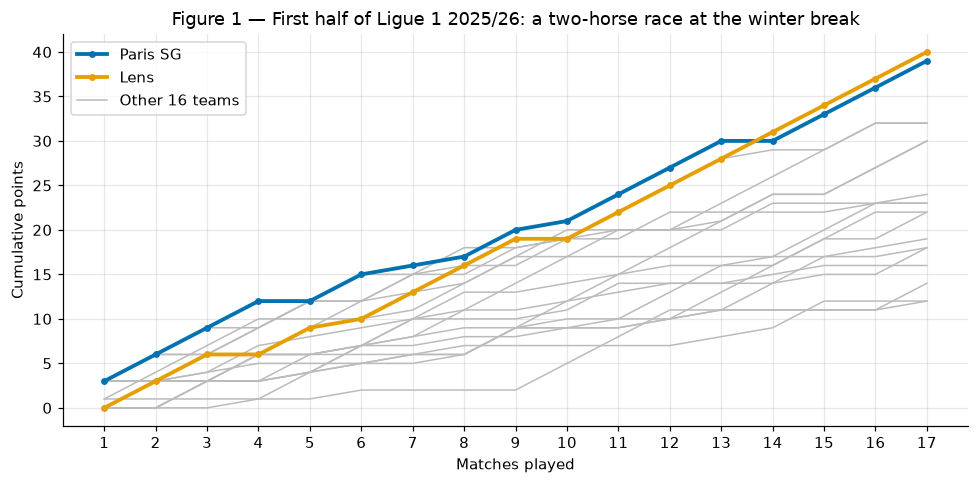

In [4]:
# Cumulative points over the first half: the two leaders against the rest of the league
long = pd.concat([
    pd.DataFrame({"team": played.home, "date": played.date, "pts": 3 * (played.hg > played.ag) + (played.hg == played.ag)}),
    pd.DataFrame({"team": played.away, "date": played.date, "pts": 3 * (played.ag > played.hg) + (played.hg == played.ag)}),
]).sort_values("date", kind="stable")
long["cum"] = long.groupby("team")["pts"].cumsum()
long["game"] = long.groupby("team").cumcount() + 1

fig, ax = plt.subplots(figsize=(9, 4.5))
for team, g in long.groupby("team"):
    if team in ("Paris SG", "Lens"):
        continue
    ax.plot(g.game, g.cum, color=COL["other"], lw=1)
for team, key in (("Paris SG", "psg"), ("Lens", "lens")):
    g = long[long.team == team]
    ax.plot(g.game, g.cum, color=COL[key], lw=2.5, marker="o", ms=3.5, label=team)
ax.plot([], [], color=COL["other"], lw=1, label="Other 16 teams")
ax.set(xlabel="Matches played", ylabel="Cumulative points", xticks=range(1, 18),
       title="Figure 1 — First half of Ligue 1 2025/26: a two-horse race at the winter break")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 1.3 — From a vague question to precise ones

"Who will be champion?" has no answer at the winter break; "*what is the probability that Paris SG becomes champion?*" does, **once we specify a probabilistic model of the remaining matches**. The investigation is organised around four precise questions:

- **Q1 — Precision.** How many simulated seasons are needed to estimate the title probability within a guaranteed margin?
- **Q2 — Correctness.** Can we verify that the simulator computes what we think, against an exact computation?
- **Q3 — Relevance of the precision.** Is the simulation error the uncertainty that matters, or does the model contribute much more?
- **Q4 — Limits.** When does plain Monte Carlo stop being informative?

---
## 2 — Mathematical foundations

### 2.1 — The estimand: a probability is an expectation

Let $M = 153$ be the number of remaining matches. The end of the season is the random vector of scores

$$Z = \big((X_m, Y_m)\big)_{m=1}^{M} \in \mathbb{N}^{2M},$$

where $X_m$ and $Y_m$ are the goals of the home and away teams in match $m$. Its distribution $P_\theta$ is given by a model with parameter $\theta$ (Section 2.5). Given the points already earned, $Z$ determines the final table up to rare exact ties, which we break with independent uniform draws (Section 3.2); we include these draws in $Z$, so that $Z$ determines the final table, hence the event

$$C = \{\text{Paris SG finishes first}\}.$$

The quantity we want is

$$\boxed{\;p(\theta) = P_\theta(C) = \mathbb{E}_\theta\big[\mathbf{1}_C(Z)\big]\;}$$

**A probability is the expectation of an indicator.** This trivial identity is the bridge to Monte Carlo: any method that estimates expectations estimates probabilities.

**Why not compute $p(\theta)$ exactly?** It is a sum over all possible ends of season. Even ignoring scores and keeping only win/draw/loss, there are $3^{153} \approx 10^{73}$ outcomes, more than the number of atoms on Earth (about $10^{50}$). Scores matter too (goal difference breaks ties), so the actual sum runs over $\mathbb{N}^{306}$. Exhaustive enumeration and deterministic quadrature are hopeless.

### 2.2 — The Monte Carlo estimator

**Definition.** Draw $N$ independent ends of season $Z_1, \dots, Z_N \sim P_\theta$ and set

$$\hat p_N = \frac{1}{N} \sum_{i=1}^{N} \mathbf{1}_C(Z_i).$$

With the course notation, $\hat p_N = \overline{B}_N$ is the sample mean of the i.i.d. Bernoulli variables $B_i = \mathbf{1}_C(Z_i) \sim \mathrm{Bernoulli}(p)$.

> **Notation.** As in the lecture notes, we distinguish the **size $n$ of the data sample** (here $n = 153$ matches, used to fit the model) from the **number $N$ of repetitions** of a random experiment (here simulated seasons). $N$ is chosen by us and is only limited by computing time.

**Proposition 1.** $\mathbb{E}[\hat p_N] = p$ and $\operatorname{Var}[\hat p_N] = \dfrac{p(1-p)}{N}$. Consequently $\hat p_N \xrightarrow[N\to\infty]{\mathbb{P}} p$.

*Proof.* By linearity, $\mathbb{E}[\hat p_N] = \frac1N \sum_i \mathbb{E}[B_i] = p$. By independence, variances add: $\operatorname{Var}[\hat p_N] = \frac{1}{N^2} \sum_i \operatorname{Var}[B_i] = \frac{p(1-p)}{N}$. Convergence in probability follows from Chebyshev's inequality for sample means (Corollary 3 of the lecture notes): $P(|\hat p_N - p| \ge \varepsilon) \le \frac{p(1-p)}{N\varepsilon^2} \to 0$. $\square$

**Interpretation.**
- *Unbiased*: on average over repeated simulations, the estimator is right; all the error is **variance**.
- *Standard error* $\sqrt{p(1-p)/N}$: it decreases as $1/\sqrt N$, **whatever the dimension of $Z$** (here 306). This is the decisive advantage of Monte Carlo over grid-based integration, whose error deteriorates with the dimension.
- *Cost of precision*: dividing the error by 10 requires **100 times** more simulations.
- *Worst case*: $p(1-p) \le 1/4$, with equality at $p = 1/2$. A tight title race is the hardest case for Monte Carlo.

### 2.3 — How many simulations? Three confidence radii

A confidence radius $r_N(\delta)$ satisfies $P\big(|\hat p_N - p| \le r_N(\delta)\big) \ge 1 - \delta$. Chapter 1 of the course provides the first two; the third comes from the central limit theorem.

**Chebyshev (distribution-free, non-asymptotic).** Using $p(1-p) \le 1/4$ in Proposition 1,
$P(|\hat p_N - p| \ge \varepsilon) \le \frac{1}{4N\varepsilon^2}$. Setting the bound equal to $\delta$ gives

$$r^{\mathrm{Cheb}}_N(\delta) = \frac{1}{2\sqrt{N\delta}}.$$

**Hoeffding (bounded variables, non-asymptotic).** The $B_i$ take values in $[0, 1]$, so Hoeffding's inequality (lecture notes, §1.3) gives $P(|\hat p_N - p| \ge \varepsilon) \le 2 e^{-2N\varepsilon^2}$, hence

$$r^{\mathrm{Hoeff}}_N(\delta) = \sqrt{\frac{\log(2/\delta)}{2N}}.$$

**Central limit theorem (asymptotic).** $\sqrt{N}(\hat p_N - p)/\sqrt{p(1-p)} \xrightarrow{d} \mathcal{N}(0,1)$, which suggests the (Wald) radius

$$r^{\mathrm{CLT}}_N(\delta) = z_{1-\delta/2}\sqrt{\frac{\hat p_N(1-\hat p_N)}{N}}.$$

| | Assumption | Guarantee | What sets the width |
|---|---|---|---|
| Chebyshev | known variance bound (here $\operatorname{Var} \le 1/4$ for $[0,1]$-valued variables) | valid for every $N$ | $1/\sqrt{\delta}$: grows fast as $\delta \to 0$ |
| Hoeffding | variables bounded in $[0, 1]$ | valid for every $N$ | $\sqrt{\log(2/\delta)/2}$: grows slowly; ignores the variance |
| CLT | finite variance | only as $N \to \infty$ | $z_{1-\delta/2} \approx \sqrt{2\log(2/\delta)}$, same order as Hoeffding, **times** $\sqrt{\hat p_N(1-\hat p_N)}$: adapts to the variance |

All three shrink at the same $1/\sqrt N$ rate; they differ by constant factors. Hoeffding and the CLT have the same dependence on $\delta$; the CLT is narrower mainly because it uses the estimated variance $\hat p_N(1-\hat p_N) \le 1/4$ instead of the worst case — at the price of a guarantee that is only asymptotic. Inverting the radii gives the number of simulations needed for a target precision $\varepsilon$.

Number of simulations N needed for |p̂ − p| ≤ ε with probability ≥ 95%


,Chebyshev,Hoeffding,CLT (p = 1/2)
precision ε,,,
0.0500,2000,738,385
0.0100,50000,18445,9604
0.0050,200000,73778,38415
0.0010,5000000,1844440,960365


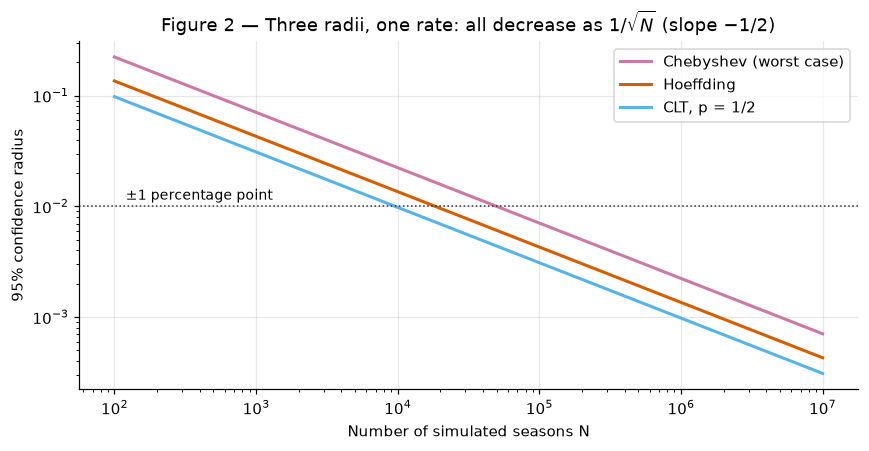

In [5]:
def radius_chebyshev(n, delta):
    """Distribution-free Chebyshev radius for a mean of [0, 1]-valued variables."""
    return 1 / (2 * np.sqrt(n * delta))


def radius_hoeffding(n, delta):
    """Hoeffding radius for a mean of [0, 1]-valued variables."""
    return np.sqrt(np.log(2 / delta) / (2 * n))


def radius_clt(n, delta, p_hat):
    """Asymptotic (Wald) radius from the central limit theorem, with the plug-in variance p_hat (1 - p_hat)."""
    return norm.ppf(1 - delta / 2) * np.sqrt(p_hat * (1 - p_hat) / n)


DELTA = 0.05
rows = []
for eps in (0.05, 0.01, 0.005, 0.001):
    rows.append({
        "precision ε": eps,
        "Chebyshev": int(np.ceil(1 / (4 * DELTA * eps**2))),
        "Hoeffding": int(np.ceil(np.log(2 / DELTA) / (2 * eps**2))),
        "CLT (p = 1/2)": int(np.ceil(norm.ppf(1 - DELTA / 2) ** 2 * 0.25 / eps**2)),
    })
print("Number of simulations N needed for |p̂ − p| ≤ ε with probability ≥ 95%")
display(pd.DataFrame(rows).set_index("precision ε"))

n_grid = np.logspace(2, 7, 200)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.loglog(n_grid, radius_chebyshev(n_grid, DELTA), color=COL["cheb"], lw=2, label="Chebyshev (worst case)")
ax.loglog(n_grid, radius_hoeffding(n_grid, DELTA), color=COL["hoeff"], lw=2, label="Hoeffding")
ax.loglog(n_grid, radius_clt(n_grid, DELTA, 0.5), color=COL["clt"], lw=2, label="CLT, p = 1/2")
ax.axhline(0.01, color=COL["exact"], ls=":", lw=1)
ax.text(1.2e2, 0.0115, "±1 percentage point", fontsize=9)
ax.set(xlabel="Number of simulated seasons N", ylabel="95% confidence radius",
       title="Figure 2 — Three radii, one rate: all decrease as $1/\\sqrt{N}$ (slope −1/2)")
ax.legend()
plt.tight_layout()
plt.show()

#### What do we observe?

- On a log–log scale the three radii are **parallel lines of slope $-1/2$**: the rate $1/\sqrt N$ is intrinsic to Monte Carlo; the inequalities only change the constant.
- For a precision of $\pm 1$ point at 95%, Hoeffding needs about $18\,000$ seasons, the CLT about $10\,000$, Chebyshev $50\,000$. Each extra decimal multiplies the cost by 100.
- These are modest numbers for a computer: we will use $N = 200\,000$, for which Hoeffding **guarantees** $\pm 0.30$ percentage points.

### 2.4 — Many probabilities at once: the union bound

The same simulations give the title probabilities of all $K = 18$ teams. Radii computed one team at a time do not guarantee that **all** intervals are simultaneously correct — the same issue as selecting one coin among many in §1.6 of the course.

**Proposition 2 (simultaneous radius).** With $r = \sqrt{\log(2K/\delta)/(2N)}$,
$P\big(\exists k \le K : |\hat p_{k,N} - p_k| > r\big) \le \delta$.

*Proof.* By Hoeffding, each event $\{|\hat p_{k,N} - p_k| > r\}$ has probability at most $2e^{-2Nr^2} = \delta/K$. The union bound $P(\cup_k A_k) \le \sum_k P(A_k)$ gives at most $K \cdot \delta/K = \delta$. $\square$

The price of simultaneity is mild: $\log(2/\delta)$ becomes $\log(2K/\delta)$. For $K = 18$ and $N = 200\,000$, the radius grows from $0.30$ to $0.41$ percentage points (about a third wider).

### 2.5 — The model is an input, not the object of study

Monte Carlo needs a way to **sample** $Z$; it does not care how sophisticated the sampler is. We therefore deliberately use the simplest credible model of football scores (Maher, 1982), and treat it as a given input of the method:

$$X_m \sim \mathrm{Poisson}(\lambda_m), \quad Y_m \sim \mathrm{Poisson}(\nu_m), \quad \text{all independent},$$

$$\log \lambda_m = \mu + h + a_{i} - d_{j}, \qquad \log \nu_m = \mu + a_{j} - d_{i},$$

for match $m$ between home team $i$ and away team $j$. Here $\mu$ sets the average scoring rate, $h$ is the home advantage, $a_i$ the attack strength of team $i$ and $d_i$ its defence strength. A value $a_i = 0.3$ means that team $i$ scores $e^{0.3} \approx 1.35$ times more than an average team against the same opponent.

- **Why Poisson?** Goals are rare events in many short time intervals; the Poisson law is the limit of such binomial counts.
- **Identifiability.** Adding a constant to all $a_i$ and all $d_i$ leaves every rate unchanged, and so does adding a constant to $\mu$ while subtracting it from all $a_i$. We impose $\sum_i a_i = \sum_i d_i = 0$.
- **Estimation.** $\theta = (\mu, h, a, d)$ (36 free parameters) is fitted by maximum likelihood on the $n = 153$ first-half matches. The log-likelihood $\sum_m \big(X_m \log\lambda_m - \lambda_m\big) + \big(Y_m\log\nu_m - \nu_m\big)$ is concave in $\theta$ (linear minus exponential of linear functions), so any local maximum found by a numerical optimiser is global; it is unique once the two centring constraints remove the flat directions (existence requires every team to have scored and conceded at least once, which holds here).
- **What we deliberately leave out** (discussed in Section 5): dependence between the two scores (Dixon & Coles, 1997), strengths evolving over time, injuries and transfers, external information such as betting odds.

### 2.6 — Two sources of uncertainty

In practice $\theta$ is unknown: we plug in its estimate $\hat\theta$, computed from the first half. Monte Carlo then estimates $p(\hat\theta)$, **not** $p(\theta)$. The estimator $\hat p_N$ is random for two reasons: the simulated seasons, and the data that produced $\hat\theta$.

**Proposition 3 (law of total variance).**
$$\operatorname{Var}[\hat p_N] = \underbrace{\mathbb{E}\Big[\frac{p(\hat\theta)\,(1 - p(\hat\theta))}{N}\Big]}_{\text{Monte Carlo error}} + \underbrace{\operatorname{Var}\big[p(\hat\theta)\big]}_{\text{parameter uncertainty}}.$$

*Proof.* For any random variables, $\operatorname{Var}[U] = \mathbb{E}[\operatorname{Var}(U \mid V)] + \operatorname{Var}[\mathbb{E}(U \mid V)]$. With $U = \hat p_N$ and $V = \hat\theta$, Proposition 1 applied conditionally on $\hat\theta$ gives $\mathbb{E}[\hat p_N \mid \hat\theta] = p(\hat\theta)$ and $\operatorname{Var}(\hat p_N \mid \hat\theta) = p(\hat\theta)(1 - p(\hat\theta))/N$. $\square$

**Interpretation.** The first term vanishes as $N \to \infty$; the second **does not depend on $N$ at all**. Beyond some point, more simulations buy no real precision. Measuring the second term (Section 4.3) answers Q3.

---
## 3 — Implementation

### 3.1 — Fitting the model (the input)

The negative log-likelihood and its gradient are written explicitly. The derivative with respect to each linear predictor $\eta = \log\lambda$ is simply $\lambda - X$ (expected minus observed goals), which makes the gradient a sum of residuals.

In [6]:
@dataclass(frozen=True)
class PoissonModel:
    """Independent Poisson goal model; attack and defence strengths are centred (identifiability)."""

    mu: float
    home: float
    att: np.ndarray
    dfn: np.ndarray

    def rates(self, h: np.ndarray, a: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Expected goals of the home and away teams for matches (h[m] at home against a[m])."""
        lam_h = np.exp(self.mu + self.home + self.att[h] - self.dfn[a])
        lam_a = np.exp(self.mu + self.att[a] - self.dfn[h])
        return lam_h, lam_a


def fit_poisson_model(h, a, hg, ag, n_teams: int = T) -> PoissonModel:
    """Maximum-likelihood fit by L-BFGS with the analytic gradient, then centring of the strengths."""

    def neg_log_lik(p):
        mu, home, att, dfn = p[0], p[1], p[2:2 + n_teams], p[2 + n_teams:]
        eta_h = mu + home + att[h] - dfn[a]
        eta_a = mu + att[a] - dfn[h]
        lam_h, lam_a = np.exp(eta_h), np.exp(eta_a)
        value = np.sum(lam_h - hg * eta_h) + np.sum(lam_a - ag * eta_a)  # constant log(x!) terms dropped
        r_h, r_a = lam_h - hg, lam_a - ag  # derivatives with respect to the linear predictors
        grad = np.empty_like(p)
        grad[0] = r_h.sum() + r_a.sum()
        grad[1] = r_h.sum()
        grad[2:2 + n_teams] = np.bincount(h, weights=r_h, minlength=n_teams) + np.bincount(a, weights=r_a, minlength=n_teams)
        grad[2 + n_teams:] = -np.bincount(a, weights=r_h, minlength=n_teams) - np.bincount(h, weights=r_a, minlength=n_teams)
        return value, grad

    res = minimize(neg_log_lik, np.zeros(2 + 2 * n_teams), jac=True, method="L-BFGS-B",
                   options={"maxiter": 5000, "gtol": 1e-8})
    if not res.success:
        raise RuntimeError(f"MLE did not converge: {res.message}")
    att, dfn = res.x[2:2 + n_teams], res.x[2 + n_teams:]
    # Centring leaves every rate unchanged: mu absorbs the means
    return PoissonModel(mu=res.x[0] + att.mean() - dfn.mean(), home=res.x[1], att=att - att.mean(), dfn=dfn - dfn.mean())


model = fit_poisson_model(played.h.to_numpy(), played.a.to_numpy(), played.hg.to_numpy(), played.ag.to_numpy())

lam_h_fit, lam_a_fit = model.rates(played.h.to_numpy(), played.a.to_numpy())
print(f"Home advantage: exp(h) = {np.exp(model.home):.3f}  (home teams score {100 * (np.exp(model.home) - 1):.0f}% more)")
print(f"Goals per match — observed: {(played.hg + played.ag).mean():.3f} | fitted: {(lam_h_fit + lam_a_fit).mean():.3f}")
strengths = pd.DataFrame({"attack a": model.att, "defence d": model.dfn}, index=TEAMS).sort_values("attack a", ascending=False)
display(strengths.T)

Home advantage: exp(h) = 1.467  (home teams score 47% more)
Goals per match — observed: 2.837 | fitted: 2.837


,Paris SG,Marseille,Lille,Lens,Rennes,Monaco,Strasbourg,Lyon,Toulouse,Brest,Paris FC,Nice,Lorient,Metz,Angers,Nantes,Le Havre,Auxerre
attack a,0.4670,0.4102,0.3438,0.2789,0.2454,0.1629,0.1184,0.0822,0.0289,-0.0319,-0.0408,-0.1349,-0.1571,-0.1843,-0.2662,-0.3599,-0.4558,-0.5067
defence d,0.4293,0.2856,0.0001,0.5643,-0.0430,-0.2766,0.1267,0.3249,0.0489,-0.1522,-0.2533,-0.2501,-0.2379,-0.4819,0.1902,-0.1670,0.0327,-0.1408


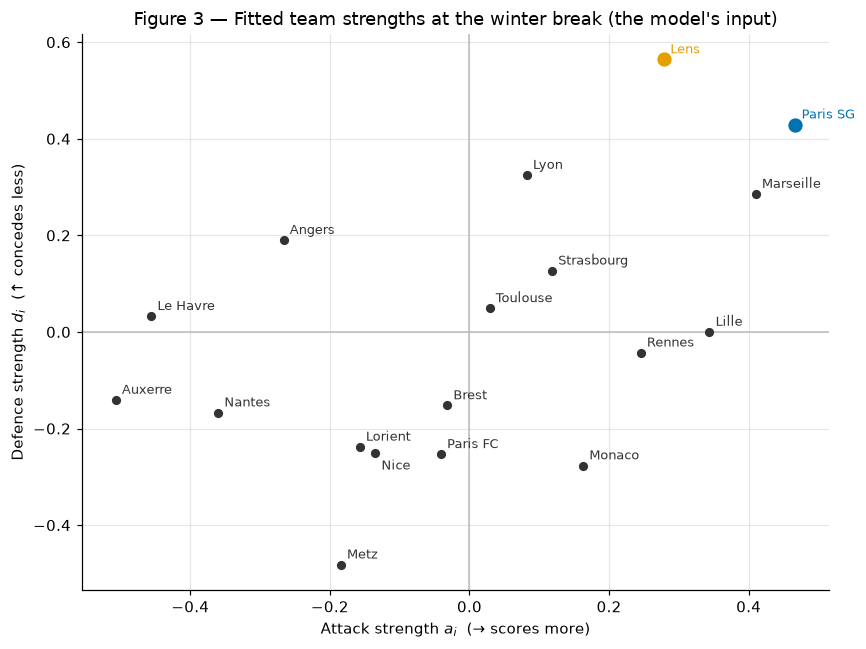

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for i, team in enumerate(TEAMS):
    color = COL["psg"] if i == PSG else COL["lens"] if i == LENS else COL["exact"]
    ax.scatter(model.att[i], model.dfn[i], color=color, s=70 if i in (PSG, LENS) else 25, zorder=3)
    offset = (4, -11) if team == "Nice" else (4, 4)  # avoid overlapping labels
    ax.annotate(team, (model.att[i], model.dfn[i]), xytext=offset, textcoords="offset points", fontsize=8.5, color=color)
ax.axhline(0, color=COL["other"], lw=1)
ax.axvline(0, color=COL["other"], lw=1)
ax.set(xlabel="Attack strength $a_i$  (→ scores more)", ylabel="Defence strength $d_i$  (↑ concedes less)",
       title="Figure 3 — Fitted team strengths at the winter break (the model's input)")
plt.tight_layout()
plt.show()

#### What do we observe?

- **The fit reproduces the scoring level exactly** (2.837 goals per match, observed and fitted). This is not a coincidence: for a Poisson model with an intercept, the likelihood equation for $\mu$ forces the sum of fitted rates to equal the sum of observed goals.
- **Home advantage is substantial**: $e^{h} \approx 1.47$, i.e. a team scores about 47% more at home than away against the same opponent.
- **Paris SG has the best attack** ($a = 0.47$: $e^{0.47} \approx 1.60$ times the average scoring rate) and the second-best defence; **Lens has the best defence by far** ($d = 0.56$: it concedes $e^{-0.56} \approx 0.57$ times the average) and the fourth-best attack.
- **The model ranks teams by goals, not by points.** Lens leads the table with 40 points, but Paris SG has the better goal difference (+22 against +18). A model fed with goals will therefore see Paris SG as the stronger team, even though it is second. Section 4.2 shows the consequence.

### 3.2 — A vectorised season simulator

A simulated season is produced in four steps:
1. draw the $2M$ scores of the remaining matches from their Poisson laws;
2. convert scores into points ($3$ / $1$ / $0$) and goal differences;
3. add them to the standings at the cutoff, using incidence matrices (one matrix product per season batch);
4. rank the teams with the Ligue 1 tie-breakers: **points, then overall goal difference**, then — as an approximation of the remaining official criteria (head-to-head points, fair play, …) — a uniform random draw.

All $N$ seasons of a batch are simulated at once with NumPy arrays of shape $(N, M)$, without any Python loop over seasons.

In [8]:
@dataclass(frozen=True)
class SeasonState:
    """What is known at a cutoff date: current points and goal difference, and the fixtures left to play."""

    base_pts: np.ndarray
    base_gd: np.ndarray
    h: np.ndarray
    a: np.ndarray

    @property
    def n_matches(self) -> int:
        return self.h.size


def season_state(cutoff: pd.Timestamp) -> SeasonState:
    """Standings before the cutoff and list of the matches played on or after it."""
    table = league_table(matches[matches.date < cutoff]).reindex(TEAMS)
    future = matches[matches.date >= cutoff]
    return SeasonState(table.Pts.to_numpy(float), table.GD.to_numpy(float), future.h.to_numpy(), future.a.to_numpy())


def simulate_goals(model: PoissonModel, state: SeasonState, n: int, rng: np.random.Generator):
    """Scores of the remaining matches for n independent seasons, arrays of shape (n, M)."""
    lam_h, lam_a = model.rates(state.h, state.a)
    size = (n, state.n_matches)
    return rng.poisson(lam_h, size).astype(np.int8), rng.poisson(lam_a, size).astype(np.int8)


def points_and_gd(state: SeasonState, gh: np.ndarray, ga: np.ndarray):
    """Final points and goal difference (n, T): standings at the cutoff plus the simulated matches."""
    inc_h, inc_a = np.eye(T)[state.h], np.eye(T)[state.a]  # (M, T) incidence matrices
    pts = state.base_pts + (3.0 * (gh > ga) + (gh == ga)) @ inc_h + (3.0 * (ga > gh) + (gh == ga)) @ inc_a
    gd = state.base_gd + (gh.astype(float) - ga) @ (inc_h - inc_a)
    return pts, gd


def final_tables(state: SeasonState, gh: np.ndarray, ga: np.ndarray, u: np.ndarray):
    """Final points (n, T) and final positions (n, T; 0 = champion) from simulated scores and tie-break draws u."""
    pts, gd = points_and_gd(state, gh, ga)
    score = 1000.0 * pts + gd + 0.5 * u  # lexicographic: points, goal difference, random draw
    order = np.argsort(-score, axis=1)
    pos = np.empty_like(order)
    np.put_along_axis(pos, order, np.arange(T)[None, :], axis=1)
    return pts.astype(np.int16), pos.astype(np.int8)


def simulate_seasons(model: PoissonModel, state: SeasonState, n: int, rng: np.random.Generator, batch: int = 50_000):
    """Simulate n independent ends of season, by batches to bound memory; returns final points and positions."""
    pts_all, pos_all = [], []
    for start in range(0, n, batch):
        b = min(batch, n - start)
        gh, ga = simulate_goals(model, state, b, rng)
        pts, pos = final_tables(state, gh, ga, rng.random((b, T)))
        pts_all.append(pts)
        pos_all.append(pos)
    return np.concatenate(pts_all), np.concatenate(pos_all)


state = season_state(CUTOFF)
N_MAIN = 200_000
pts_mc, pos_mc = simulate_seasons(model, state, N_MAIN, make_rng(1))
title_mc = pos_mc == 0  # Bernoulli indicators 1_C(Z_i), one column per team
p_hat = title_mc.mean(axis=0)

print(f"N = {N_MAIN:,} simulated seasons of {state.n_matches} matches")
print(f"P̂(Paris SG champion) = {p_hat[PSG]:.4f} | P̂(Lens champion) = {p_hat[LENS]:.4f}")

# Cost of the tie-break approximation: how often are the first two level on points AND goal difference?
pts_chk, gd_chk = points_and_gd(state, *simulate_goals(model, state, 50_000, make_rng(2)))
key = np.sort(1000 * pts_chk + gd_chk, axis=1)
print(f"Title decided by the random draw (top two level on points and goal difference): {np.mean(key[:, -1] == key[:, -2]):.2%} of seasons")

N = 200,000 simulated seasons of 153 matches
P̂(Paris SG champion) = 0.5621 | P̂(Lens champion) = 0.4078
Title decided by the random draw (top two level on points and goal difference): 0.21% of seasons


### 3.3 — Exact validation: is the simulator right?

A simulator can be fast, plausible and wrong. Since the title probability itself cannot be computed exactly, we validate the simulator on a related quantity that **can**: the joint law of the final points of Paris SG and Lens.

Under the model, matches are independent. The points a team earns in one match take values in $\{0, 1, 3\}$ with probabilities

$$P(X > Y) = \sum_{x > y} \pi_\lambda(x)\,\pi_\nu(y), \qquad P(X = Y) = \sum_{x} \pi_\lambda(x)\,\pi_\nu(x),$$

where $\pi_\lambda$ is the Poisson probability mass function (sums truncated at 30 goals; the largest expected score is about 4, so the neglected mass is below $10^{-15}$). The law of a sum of independent variables is the **convolution** of their laws, so the distribution of a team's final points is computed exactly in $17$ convolutions. Paris SG and Lens are dependent only through their head-to-head match; conditioning on its three possible outcomes restores independence:

$$P(\text{PSG points} > \text{Lens points}) = \sum_{o \in \{\text{PSG win, draw, Lens win}\}} P(o)\; P\big(S_{\text{PSG}} + \Delta_{\text{PSG}}(o) > S_{\text{Lens}} + \Delta_{\text{Lens}}(o)\big),$$

with $S$ the points earned in the other 16 matches, independent across the two teams.

In [9]:
def outcome_probs(lam_h: np.ndarray, lam_a: np.ndarray, gmax: int = 30):
    """Exact home-win / draw / away-win probabilities of independent Poisson scores (truncated at gmax goals)."""
    k = np.arange(gmax + 1)
    joint = poisson.pmf(k, lam_h[:, None])[:, :, None] * poisson.pmf(k, lam_a[:, None])[:, None, :]  # [m, x, y]
    p_home = np.tril(joint, -1).sum(axis=(1, 2))  # x > y
    p_draw = np.trace(joint, axis1=1, axis2=2)
    return p_home, p_draw, 1 - p_home - p_draw


P_HOME, P_DRAW, P_AWAY = outcome_probs(*model.rates(state.h, state.a))


def points_pmf(team: int, keep: np.ndarray) -> np.ndarray:
    """Exact law of the points earned by `team` in the remaining matches selected by `keep` (convolution)."""
    pmf = np.array([1.0])
    for m in np.flatnonzero(keep & ((state.h == team) | (state.a == team))):
        p_win, p_loss = (P_HOME[m], P_AWAY[m]) if state.h[m] == team else (P_AWAY[m], P_HOME[m])
        new = np.zeros(pmf.size + 3)
        new[:pmf.size] += p_loss * pmf
        new[1:pmf.size + 1] += P_DRAW[m] * pmf
        new[3:] += p_win * pmf
        pmf = new
    return pmf


H2H = int(np.flatnonzero((state.h == LENS) & (state.a == PSG))[0])  # Lens – Paris SG, 13 May 2026
others = np.ones(state.n_matches, dtype=bool)
others[H2H] = False
pmf_psg_16, pmf_lens_16 = points_pmf(PSG, others), points_pmf(LENS, others)
gap = (state.base_pts[PSG] + np.arange(pmf_psg_16.size))[:, None] - (state.base_pts[LENS] + np.arange(pmf_lens_16.size))[None, :]
joint16 = np.outer(pmf_psg_16, pmf_lens_16)
h2h_cases = [(P_AWAY[H2H], 3, 0), (P_DRAW[H2H], 1, 1), (P_HOME[H2H], 0, 3)]  # (probability, PSG pts, Lens pts)
exact = {
    "PSG > Lens": sum(p * joint16[gap + dp - dl > 0].sum() for p, dp, dl in h2h_cases),
    "PSG = Lens": sum(p * joint16[gap + dp - dl == 0].sum() for p, dp, dl in h2h_cases),
}
exact["PSG < Lens"] = 1 - exact["PSG > Lens"] - exact["PSG = Lens"]

diff_mc = pts_mc[:, PSG].astype(int) - pts_mc[:, LENS]
mc = {"PSG > Lens": (diff_mc > 0).mean(), "PSG = Lens": (diff_mc == 0).mean(), "PSG < Lens": (diff_mc < 0).mean()}
r_hoeff = radius_hoeffding(N_MAIN, DELTA)
validation = pd.DataFrame({"exact": exact, "Monte Carlo": mc})
validation["|error|"] = (validation["Monte Carlo"] - validation["exact"]).abs()
validation["Hoeffding radius"] = r_hoeff
validation["within radius"] = validation["|error|"] <= r_hoeff
validation["z-score"] = (validation["Monte Carlo"] - validation["exact"]) / np.sqrt(validation["exact"] * (1 - validation["exact"]) / N_MAIN)
display(validation)

# Why P(title) differs from P(PSG > Lens on points): decomposition on the same simulations
level = diff_mc == 0
third_champ = title_mc[:, PSG] == title_mc[:, LENS]  # neither PSG nor Lens is champion
print(f"P(PSG > Lens) = {mc['PSG > Lens']:.4f} + P(level on points and PSG champion) = {np.mean(level & title_mc[:, PSG]):.4f} "
      f"- P(PSG > Lens but a third team champion) = {np.mean((diff_mc > 0) & third_champ):.4f} = P(PSG champion) = {p_hat[PSG]:.4f}")

# One run is one draw: repeat the comparison on 200 independent runs to test the simulator statistically
z = norm.ppf(1 - DELTA / 2)
R_VAL, N_VAL = 200, 20_000
p_exact = exact["PSG > Lens"]
z_runs = []
for r_ in range(R_VAL):
    pts_r, _ = simulate_seasons(model, state, N_VAL, make_rng(100 + r_))
    p_r = np.mean(pts_r[:, PSG].astype(int) > pts_r[:, LENS])
    z_runs.append((p_r - p_exact) / np.sqrt(p_exact * (1 - p_exact) / N_VAL))
z_runs = np.array(z_runs)
print(f"Standardised errors on P(PSG > Lens) over {R_VAL} independent runs of N = {N_VAL:,}: "
      f"mean = {z_runs.mean():.2f}, sd = {z_runs.std(ddof=1):.2f}, max |z| = {np.abs(z_runs).max():.2f} "
      f"(a correct simulator gives mean ≈ 0 ± {z / np.sqrt(R_VAL):.2f} and sd ≈ 1 ± {z / np.sqrt(2 * (R_VAL - 1)):.2f})")
bias = z_runs.mean() * np.sqrt(p_exact * (1 - p_exact) / N_VAL)  # pooled Monte Carlo minus exact
radius_bias = z * np.sqrt(p_exact * (1 - p_exact) / (R_VAL * N_VAL))
print(f"Pooled over {R_VAL * N_VAL:,} seasons: Monte Carlo − exact = {bias:+.5f} ± {radius_bias:.5f} (95%) "
      f"→ any bias is below {abs(bias) + radius_bias:.4f}")

,exact,Monte Carlo,|error|,Hoeffding radius,within radius,z-score
PSG > Lens,0.5294,0.5265,0.0029,0.0030,True,-2.5579
PSG = Lens,0.0579,0.0584,0.0005,0.0030,True,0.9655
PSG < Lens,0.4127,0.4151,0.0024,0.0030,True,2.1352


P(PSG > Lens) = 0.5265 + P(level on points and PSG champion) = 0.0489 - P(PSG > Lens but a third team champion) = 0.0132 = P(PSG champion) = 0.5621
Standardised errors on P(PSG > Lens) over 200 independent runs of N = 20,000: mean = 0.15, sd = 0.96, max |z| = 2.61 (a correct simulator gives mean ≈ 0 ± 0.14 and sd ≈ 1 ± 0.10)
Pooled over 4,000,000 seasons: Monte Carlo − exact = +0.00053 ± 0.00049 (95%) → any bias is below 0.0010


Total variation distance: observed 0.0055 | expected from sampling noise alone ≈ 0.0041


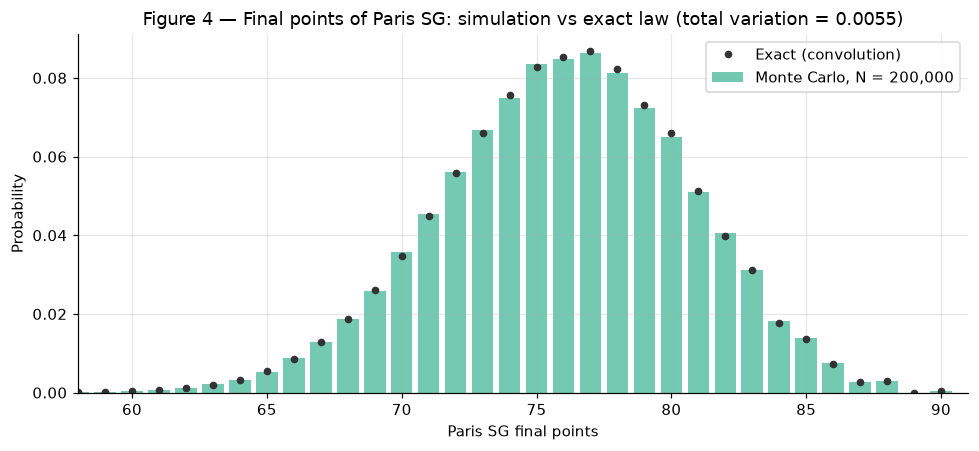

In [10]:
pmf_psg_all = points_pmf(PSG, np.ones(state.n_matches, dtype=bool))
support = state.base_pts[PSG] + np.arange(pmf_psg_all.size)
freq_mc = np.bincount(pts_mc[:, PSG] - int(state.base_pts[PSG]), minlength=pmf_psg_all.size) / N_MAIN
tv = 0.5 * np.abs(freq_mc - pmf_psg_all).sum()
tv_noise = 0.5 * np.sum(np.sqrt(2 * pmf_psg_all * (1 - pmf_psg_all) / (np.pi * N_MAIN)))  # E|f - p| ≈ sqrt(2p(1-p)/(πN)) per bin
print(f"Total variation distance: observed {tv:.4f} | expected from sampling noise alone ≈ {tv_noise:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(support, freq_mc, width=0.8, color=COL["mc"], alpha=0.55, label=f"Monte Carlo, N = {N_MAIN:,}")
ax.plot(support, pmf_psg_all, "o", color=COL["exact"], ms=4, label="Exact (convolution)")
visible = support[pmf_psg_all > 1e-4]
ax.set(xlim=(visible.min() - 1, visible.max() + 1),
       xlabel="Paris SG final points", ylabel="Probability",
       title=f"Figure 4 — Final points of Paris SG: simulation vs exact law (total variation = {tv:.4f})")
ax.legend()
plt.tight_layout()
plt.show()

#### What do we observe?

- **The simulator reproduces the exact law.** The three probabilities computed by Monte Carlo fall within the Hoeffding radius of their exact values, and the simulated histogram of Paris SG's final points (Figure 4) overlays the exact convolution almost perfectly.
- **A single run is a single random draw.** This particular run is somewhat unlucky: the error on $P(\text{PSG} > \text{Lens})$ is $2.6$ standard deviations, and the total variation distance ($0.0055$) is above its expected value under pure sampling noise ($\approx 0.0041$). Taken alone, this could signal a bug — or bad luck.
- **A simulation cannot prove the absence of bias; it can bound it.** Over 200 further independent runs, the standardised errors have standard deviation $0.96$ (expected $1 \pm 0.10$) and a maximum of $2.6$ in absolute value (typical for 200 normal draws), so the simulator's **variance** is exactly the binomial one. Their mean, $0.15$, sits at the edge of its $\pm 0.14$ band: pooled over 4 million seasons, the simulated probability exceeds the exact one by $0.0005 \pm 0.0005$. Either this is a $2\sigma$ fluctuation (expected now and then when many tests are run) or a bias — but in any case **a bias below $0.001$**: three times smaller than the Hoeffding radius of our main estimate, and 200 times smaller than the model uncertainty of Section 4.3. For the purpose of this study, the simulator is validated.
- **The title probability is not $P(\text{PSG} > \text{Lens})$.** On the same simulations, $0.5621 = 0.5265 + 0.0489 - 0.0132$: Paris SG gains $4.9$ points from the seasons where both teams finish level on points (goal difference then decides, and Paris SG starts with a +4 advantage and the stronger attack), and loses $1.3$ points from the seasons where it finishes above Lens but a third team wins the title.
- The random draw used beyond goal difference decides the title in only **0.2%** of seasons: approximating the remaining official criteria changes the title probabilities by at most this amount.

### 3.4 — Common random numbers: what is the head-to-head worth?

Lens – Paris SG on 13 May 2026 looks decisive. How much does its result change the title probability? We want

$$\Delta = P(C \mid \text{Lens } 0\text{–}1 \text{ PSG}) - P(C \mid \text{Lens } 1\text{–}0 \text{ PSG})$$

(scores written home–away, as everywhere in this notebook).

The naive approach estimates the two probabilities with **independent** simulations. A better one uses **common random numbers (CRN)**: the same $N$ simulated seasons, in which only the head-to-head score is changed. With paired indicators $(I_i^{\text{win}}, I_i^{\text{loss}})$,

$$\operatorname{Var}\big[\hat\Delta^{\mathrm{CRN}}\big] = \frac{\operatorname{Var}[I^{\text{win}}] + \operatorname{Var}[I^{\text{loss}}] - 2\operatorname{Cov}(I^{\text{win}}, I^{\text{loss}})}{N}, \qquad \operatorname{Var}\big[\hat\Delta^{\mathrm{indep}}\big] = \frac{\operatorname{Var}[I^{\text{win}}] + \operatorname{Var}[I^{\text{loss}}]}{N}.$$

Both estimators are unbiased; CRN wins whenever the covariance is positive. Here it is, by a **monotonicity** argument: in a given simulated season, changing a defeat into a win gives Paris SG 3 more points and a better goal difference, takes 3 points and goal difference away from Lens, and leaves everything else unchanged. So if Paris SG is champion after losing, it is also champion after winning: $I^{\text{loss}} \le I^{\text{win}}$. With $p_1 = P(C \mid \text{win})$, $p_2 = P(C \mid \text{loss})$, this gives $\operatorname{Cov}(I^{\text{win}}, I^{\text{loss}}) = p_2 - p_1 p_2 = p_2(1-p_1) \ge 0$ and $I^{\text{win}} - I^{\text{loss}} \in \{0, 1\}$, hence the exact variance ratio

$$\frac{\operatorname{Var}[\hat\Delta^{\mathrm{indep}}]}{\operatorname{Var}[\hat\Delta^{\mathrm{CRN}}]} = \frac{p_1(1-p_1) + p_2(1-p_2)}{\Delta(1-\Delta)},$$

which is large when $\Delta$ is small, i.e. when the two scenarios rarely lead to different champions.

In [11]:
def title_given_h2h(gh, ga, u, score):
    """Paris SG title indicators when the head-to-head score is forced to `score` = (Lens goals, PSG goals)."""
    gh, ga = gh.copy(), ga.copy()
    gh[:, H2H], ga[:, H2H] = score
    return final_tables(state, gh, ga, u)[1][:, PSG] == 0


def compare_scenarios(score_1, score_2, n: int, rng: np.random.Generator) -> dict:
    """Estimate P(C | score_1) - P(C | score_2) with common random numbers and with independent runs."""
    gh, ga = simulate_goals(model, state, n, rng)
    u = rng.random((n, T))
    i_1, i_2 = title_given_h2h(gh, ga, u, score_1), title_given_h2h(gh, ga, u, score_2)  # same random numbers
    gh2, ga2 = simulate_goals(model, state, n, rng)
    i_2_indep = title_given_h2h(gh2, ga2, rng.random((n, T)), score_2)  # fresh random numbers
    se_crn = (i_1.astype(float) - i_2).std(ddof=1) / np.sqrt(n)
    se_ind = np.sqrt(i_1.var(ddof=1) / n + i_2_indep.var(ddof=1) / n)
    return {
        "P(C | scenario 1)": i_1.mean(), "P(C | scenario 2)": i_2.mean(),
        "Δ (CRN)": i_1.mean() - i_2.mean(), "95% radius CRN": z * se_crn,
        "Δ (independent)": i_1.mean() - i_2_indep.mean(), "95% radius indep.": z * se_ind,
        "variance ratio": (se_ind / se_crn) ** 2,
        "theoretical ratio": (i_1.mean() * (1 - i_1.mean()) + i_2.mean() * (1 - i_2.mean())) / ((i_1.mean() - i_2.mean()) * (1 - i_1.mean() + i_2.mean())),
    }


N_CRN = 50_000
z = norm.ppf(1 - DELTA / 2)
crn = pd.DataFrame({
    "Lens 0–1 PSG vs Lens 1–0 PSG": compare_scenarios((0, 1), (1, 0), N_CRN, make_rng(3)),
    "Lens 0–2 PSG vs Lens 0–1 PSG": compare_scenarios((0, 2), (0, 1), N_CRN, make_rng(9)),
}).T
display(crn)

,P(C | scenario 1),P(C | scenario 2),Δ (CRN),95% radius CRN,Δ (independent),95% radius indep.,variance ratio,theoretical ratio
Lens 0–1 PSG vs Lens 1–0 PSG,0.7667,0.4243,0.3424,0.0042,0.3386,0.0057,1.8817,1.8792
Lens 0–2 PSG vs Lens 0–1 PSG,0.7690,0.7659,0.0031,0.0005,0.0054,0.0052,117.4135,117.0039


#### What do we observe?

- **The head-to-head is a "six-pointer".** Winning at Lens raises Paris SG's title probability from $0.42$ to $0.77$: $\Delta \approx 0.34$.
- **For this comparison, CRN only halves the variance** (ratio $1.88$, exactly the theoretical value $1.88$ given by the formula above). The two scenarios are very different: the champion changes in a third of the seasons ($\Delta \approx 0.34$), so $\Delta(1-\Delta)$ is not small.
- **For nearby scenarios, CRN is decisive.** Winning $0$–$2$ instead of $0$–$1$ changes only the goal difference. With CRN, $\Delta = 0.0031 \pm 0.0005$: a small but clearly positive effect. With independent runs, $\Delta = 0.0054 \pm 0.0052$: the interval barely excludes zero and is ten times wider. The variance ratio is $117$ (theory: $117$): independent runs would need **117 times more simulations** to reach the same precision.
- **Lesson.** CRN is most useful exactly when it is most needed: in sensitivity analysis ("what if this one detail changed?"), where the effect is small and independent runs drown it in noise.

---
## 4 — Results and interpretation

### 4.1 — Convergence and coverage: do the guarantees hold?

We first look at a single run: the running estimate $\hat p_N$ for Paris SG as $N$ grows, with the three 95% radii around it.

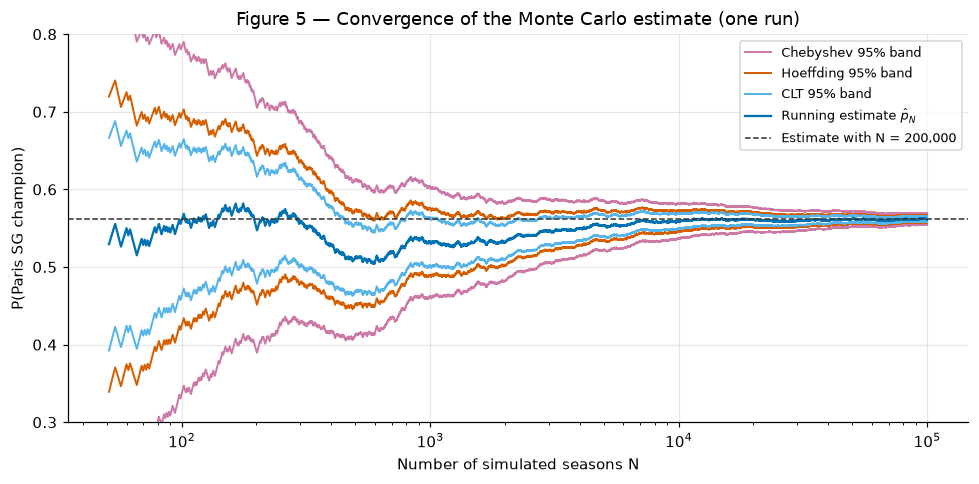

Chebyshev band misses the N = 200,000 estimate for     0 values of N
Hoeffding band misses the N = 200,000 estimate for    73 values of N, between N = 580 and N = 2012
      CLT band misses the N = 200,000 estimate for  1986 values of N, between N = 450 and N = 3129


In [12]:
n_show = 100_000
running = np.cumsum(title_mc[:n_show, PSG]) / np.arange(1, n_show + 1)
ns = np.arange(1, n_show + 1)
start = 50

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, r, key in (
    ("Chebyshev", radius_chebyshev(ns, DELTA), "cheb"),
    ("Hoeffding", radius_hoeffding(ns, DELTA), "hoeff"),
    ("CLT", radius_clt(ns, DELTA, running), "clt"),
):
    ax.plot(ns[start:], (running + r)[start:], color=COL[key], lw=1.3, label=f"{name} 95% band")
    ax.plot(ns[start:], (running - r)[start:], color=COL[key], lw=1.3)
ax.plot(ns[start:], running[start:], color=COL["psg"], lw=1.5, label="Running estimate $\\hat p_N$")
ax.axhline(p_hat[PSG], color=COL["exact"], ls="--", lw=1, label=f"Estimate with N = {N_MAIN:,}")
ax.set(xscale="log", ylim=(0.3, 0.8), xlabel="Number of simulated seasons N", ylabel="P(Paris SG champion)",
       title="Figure 5 — Convergence of the Monte Carlo estimate (one run)")
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

# Along this single path, for which N does each band miss the final estimate?
for name, r in (("Chebyshev", radius_chebyshev(ns, DELTA)), ("Hoeffding", radius_hoeffding(ns, DELTA)),
                ("CLT", radius_clt(ns, DELTA, running))):
    miss = np.flatnonzero(np.abs(running - p_hat[PSG]) > r)[np.flatnonzero(np.abs(running - p_hat[PSG]) > r) >= start] + 1
    print(f"{name:>9} band misses the N = {N_MAIN:,} estimate for {miss.size:5d} values of N"
          + (f", between N = {miss.min()} and N = {miss.max()}" if miss.size else ""))

A single run cannot tell whether "95%" is honest. The meaning of a confidence guarantee is **frequentist**: over many independent repetitions, at least 95% of the intervals must contain the true value. We therefore repeat the experiment $R = 1\,000$ times with only $N = 500$ seasons each, and count how often each interval contains the reference value (the $N = 200\,000$ estimate, whose own error, about $0.1$ point, is negligible at this scale). We do it for Paris SG ($p \approx 1/2$, $Np \approx 280$), for the third most likely champion ($Np \approx 13$) and for the fourth one ($Np \approx 1$). With $R = 1\,000$ repetitions, a coverage estimate is itself uncertain by about $\pm 1.4$ points (95%).

In [13]:
R, N_SMALL = 1_000, 500
_, pos_cov = simulate_seasons(model, state, R * N_SMALL, make_rng(4))
blocks = (pos_cov == 0).reshape(R, N_SMALL, T).mean(axis=1)  # (R, T): one estimate per repetition
third, fourth = (int(i) for i in np.argsort(-p_hat)[2:4])

rows = []
for team in (PSG, third, fourth):
    est, ref = blocks[:, team], p_hat[team]
    for name, r in (
        ("Chebyshev", np.full(R, radius_chebyshev(N_SMALL, DELTA))),
        ("Hoeffding", np.full(R, radius_hoeffding(N_SMALL, DELTA))),
        ("CLT (Wald)", radius_clt(N_SMALL, DELTA, est)),
    ):
        cov = np.mean(np.abs(est - ref) <= r)
        rows.append({"team": f"{TEAMS[team]} (p ≈ {ref:.4f})", "radius": name, "coverage": cov,
                     "± (95%, R reps)": z * np.sqrt(cov * (1 - cov) / R), "mean half-width": r.mean(),
                     "runs with p̂ = 0": np.mean(est == 0)})
coverage = pd.DataFrame(rows).set_index(["team", "radius"])
print(f"Coverage of nominal 95% intervals over R = {R} repetitions of N = {N_SMALL} seasons")
display(coverage)

Coverage of nominal 95% intervals over R = 1000 repetitions of N = 500 seasons


coverage  ± (95%, R reps)  mean half-width  \
team                   radius                                                   
Paris SG (p ≈ 0.5621)  Chebyshev     1.0000           0.0000           0.1000   
                       Hoeffding     0.9950           0.0044           0.0607   
                       CLT (Wald)    0.9470           0.0139           0.0434   
Marseille (p ≈ 0.0266) Chebyshev     1.0000           0.0000           0.1000   
                       Hoeffding     1.0000           0.0000           0.0607   
                       CLT (Wald)    0.9380           0.0149           0.0139   
Lille (p ≈ 0.0022)     Chebyshev     1.0000           0.0000           0.1000   
                       Hoeffding     1.0000           0.0000           0.0607   
                       CLT (Wald)    0.6400           0.0298           0.0031   

                                   runs with p̂ = 0  
team                   radius                        
Paris SG (p ≈ 0.5621)  Chebyshev             0.0000  
                       Hoeffding             0.0000  
                       CLT (Wald)            0.0000  
Marseille (p ≈ 0.0266) Chebyshev             0.0000  
                       Hoeffding             0.0000  
                       CLT (Wald)            0.0000  
Lille (p ≈ 0.0022)     Chebyshev             0.3600  
                       Hoeffding             0.3600  
                       CLT (Wald)            0.3600

#### What do we observe?

**On one run (Figure 5).**
- The estimate fluctuates strongly for small $N$ (between $0.50$ and $0.58$ for $N < 1\,000$), then stabilises; the bands shrink at the predicted $1/\sqrt N$ rate and keep the same ordering at every $N$: Chebyshev ⊃ Hoeffding ⊃ CLT.
- **Along this single path, the CLT band misses the final value for almost two thousand values of $N$ (between $450$ and $3\,129$), and even the non-asymptotic Hoeffding band misses it around $N \approx 600$–$2\,000$.** This is not a contradiction: "95%" holds for each **fixed** $N$, not simultaneously for all $N$ along one path. Watching a running estimate and stopping when it "looks stable" is not covered by these guarantees.

**Over 1 000 repetitions (table).** Coverage estimates are themselves uncertain by about $\pm 1.4$ points.

| | Paris SG ($Np \approx 280$) | Marseille ($Np \approx 13$) | Lille ($Np \approx 1.1$) |
|---|---|---|---|
| Chebyshev | 100%, half-width $0.100$ | 100%, half-width $0.100$ (≈ 4 × $p$) | 100%, half-width $0.100$ (≈ 45 × $p$) |
| Hoeffding | 99.5%, half-width $0.061$ | 100%, half-width $0.061$ | 100%, half-width $0.061$ |
| CLT (Wald) | **94.7%**, half-width $0.043$ | **93.8%**, half-width $0.014$ | **64%**, half-width $0.003$ |

- **Non-asymptotic guarantees are conservative.** Chebyshev and Hoeffding hold for every $N$, but at the price of intervals 2.3 and 1.4 times wider than the CLT one near $p = 1/2$. This is the trade-off of Chapter 1: guaranteed but pessimistic versus approximate but sharp.
- **Distribution-free bounds ignore the variance.** For a small $p$ they are valid but uninformative (a half-width 45 times the quantity estimated for Lille). Variance-aware bounds (the Bernoulli-specific Chebyshev radius of Exercise 8, Bernstein's inequality) would be much tighter.
- **The CLT is accurate as long as $Np$ is large** — both Paris SG and Marseille are compatible with 95% — **and collapses when $Np \approx 1$**: for Lille, 36% of the runs never see Lille champion, $\hat p_N = 0$, and the Wald interval reduces to $\{0\}$, which excludes the truth. Coverage falls to 64%. Score-based intervals (Wilson) are the standard remedy; Section 5.2 pushes this regime to its extreme.

### 4.2 — The answer under the model: title probabilities

In [14]:
r_simul = np.sqrt(np.log(2 * T / DELTA) / (2 * N_MAIN))  # simultaneous Hoeffding radius (Proposition 2)
order = np.argsort(-p_hat)
contenders = [i for i in order if p_hat[i] > 0]
res_table = pd.DataFrame({
    "P(champion)": [f"{p_hat[i]:.4f}" if p_hat[i] >= 1e-3 else f"{p_hat[i]:.1e}" for i in contenders],
    "simultaneous 95% interval": [f"[{max(p_hat[i] - r_simul, 0):.4f}, {min(p_hat[i] + r_simul, 1):.4f}]" for i in contenders],
    "points at the cutoff": state.base_pts[contenders].astype(int),
}, index=[TEAMS[i] for i in contenders])
print(f"N = {N_MAIN:,} | simultaneous Hoeffding radius for K = {T} teams: ±{r_simul:.4f}")
display(res_table)

N = 200,000 | simultaneous Hoeffding radius for K = 18 teams: ±0.0041


,P(champion),simultaneous 95% interval,points at the cutoff
Paris SG,0.5621,"[0.5581, 0.5662]",39
Lens,0.4078,"[0.4038, 0.4119]",40
Marseille,0.0266,"[0.0225, 0.0306]",32
Lille,0.0022,"[0.0000, 0.0062]",32
Lyon,0.0011,"[0.0000, 0.0051]",30
Rennes,2.2e-04,"[0.0000, 0.0043]",30
Strasbourg,5.0e-06,"[0.0000, 0.0041]",24


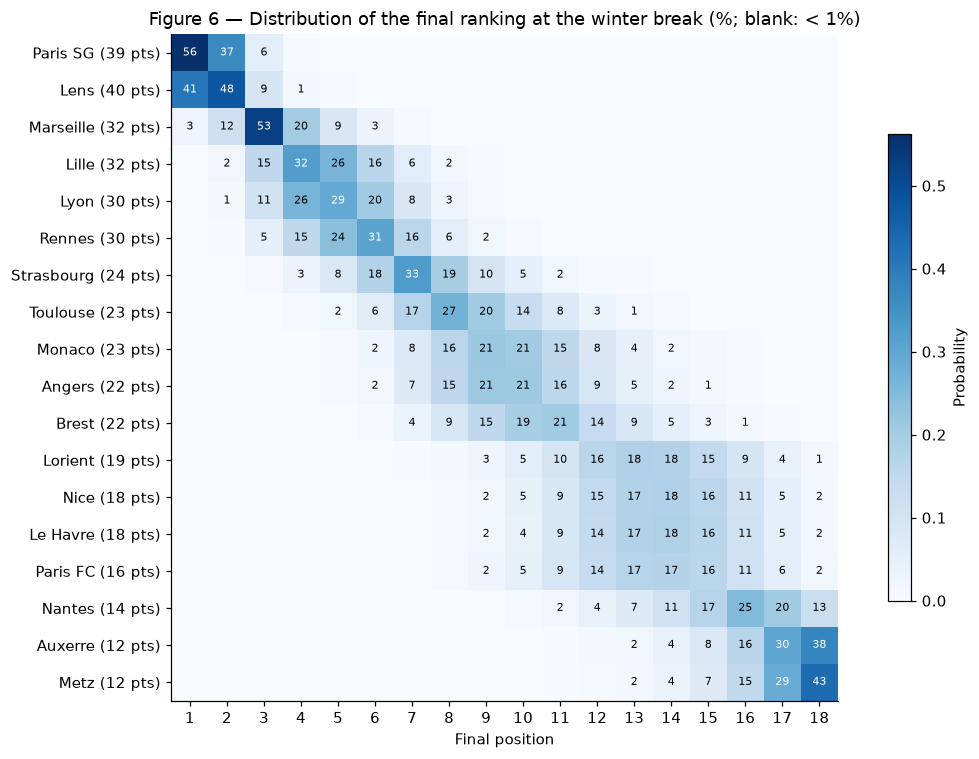

In [15]:
# Probability of each final position for each team, teams sorted by expected position
pos_prob = np.stack([np.bincount(pos_mc[:, i], minlength=T) / N_MAIN for i in range(T)])  # [team, position]
sorted_teams = np.argsort(pos_prob @ np.arange(T))

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(pos_prob[sorted_teams], cmap="Blues", vmin=0, vmax=pos_prob.max())
for r_, i in enumerate(sorted_teams):
    for k in range(T):
        if pos_prob[i, k] >= 0.01:
            ax.text(k, r_, f"{100 * pos_prob[i, k]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if pos_prob[i, k] > 0.5 * pos_prob.max() else "black")
ax.set_xticks(range(T), range(1, T + 1))
ax.set_yticks(range(T), [f"{TEAMS[i]} ({int(state.base_pts[i])} pts)" for i in sorted_teams])
ax.set(xlabel="Final position", title="Figure 6 — Distribution of the final ranking at the winter break (%; blank: < 1%)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Probability")
plt.tight_layout()
plt.show()

#### What do we observe?

- **Under the model, Paris SG is the favourite despite trailing**: $P(\text{champion}) = 0.562$ against $0.408$ for Lens, with a simultaneous guarantee of $\pm 0.004$. Marseille keeps a residual 2.7% chance; every other team is below 0.3%.
- **Why the second-placed team is favourite.** The deficit is only one point, Paris SG's goal record is better (more goals scored, similar goals conceded), and the model judges strength from goals. Over 17 remaining matches, a small edge in strength outweighs a one-point lead.
- **Figure 6 shows that the whole table comes for free.** The same 200 000 simulations give every team's probability of every position: Paris SG finishes first or second in 93% of seasons, Lens in 89%; Marseille is the clear third (53%); at the bottom, Metz and Auxerre are relegated directly (positions 17–18) in about 70% of seasons each.
- **Simultaneous intervals matter.** The table reports 18 estimates at once; the union bound guarantees that **all** of them are within $\pm 0.0041$ of their target with probability at least 95%, for only about a third more width than a single interval.

**Answer to Q1:** about $18\,000$ simulated seasons guarantee $\pm 1$ point (Hoeffding); with $N = 200\,000$ the guaranteed precision is $\pm 0.3$ point per team and $\pm 0.4$ point simultaneously for the 18 teams.

### 4.3 — Simulation error vs model uncertainty

The numbers above are **exact up to $\pm 0.4$ point — for the fitted model**. But $\hat\theta$ was estimated from only 153 matches (17 per team for 36 parameters). How much would $p(\hat\theta)$ move if the first half had been replayed?

We estimate the second term of Proposition 3 with a **parametric bootstrap**, itself a Monte Carlo method:
1. simulate a new first half from the fitted model $P_{\hat\theta}$ (same 153 fixtures);
2. refit the model on it, giving $\hat\theta^*_b$;
3. estimate $p(\hat\theta^*_b)$ by simulating $N_{\text{in}}$ seasons from the **real** standings at the cutoff;
4. repeat for $b = 1, \dots, B$.

The bootstrap estimates are themselves noisy: by Proposition 3 applied to them, their variance is $\operatorname{Var}[p(\hat\theta^*)] + \mathbb{E}[p(1-p)]/N_{\text{in}}$. We subtract an unbiased estimate of the second term, $\overline{\hat p^*(1-\hat p^*)}/(N_{\text{in}}-1)$, to isolate the parameter uncertainty.

In [16]:
B, N_IN = 200, 5_000
rng = make_rng(5)
ph_, pa_ = played.h.to_numpy(), played.a.to_numpy()
lam_h1, lam_a1 = model.rates(ph_, pa_)
boot = np.empty((B, T))
for b in range(B):
    model_b = fit_poisson_model(ph_, pa_, rng.poisson(lam_h1), rng.poisson(lam_a1))
    boot[b] = (simulate_seasons(model_b, state, N_IN, rng)[1] == 0).mean(axis=0)

for team in (PSG, LENS):
    var_total = boot[:, team].var(ddof=1)
    var_inner = np.mean(boot[:, team] * (1 - boot[:, team])) / (N_IN - 1)  # unbiased inner Monte Carlo noise
    sd_param = np.sqrt(max(var_total - var_inner, 0))
    sd_mc = np.sqrt(p_hat[team] * (1 - p_hat[team]) / N_MAIN)
    lo, hi = np.percentile(boot[:, team], [2.5, 97.5])
    print(f"{TEAMS[team]:>9}: p̂ = {p_hat[team]:.3f} | Monte Carlo sd (N = {N_MAIN:,}) = {sd_mc:.4f} | "
          f"parameter sd = {sd_param:.3f} (ratio {sd_param / sd_mc:.0f}x) | bootstrap 95% range [{lo:.2f}, {hi:.2f}]")

 Paris SG: p̂ = 0.562 | Monte Carlo sd (N = 200,000) = 0.0011 | parameter sd = 0.231 (ratio 209x) | bootstrap 95% range [0.12, 0.95]
     Lens: p̂ = 0.408 | Monte Carlo sd (N = 200,000) = 0.0011 | parameter sd = 0.227 (ratio 207x) | bootstrap 95% range [0.03, 0.84]


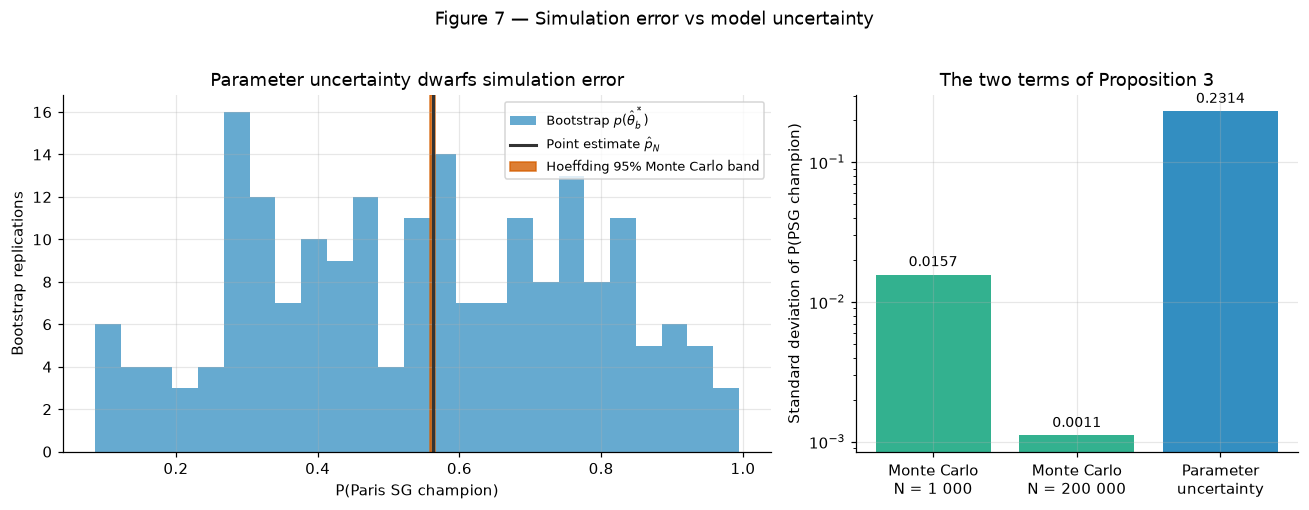

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.hist(boot[:, PSG], bins=25, color=COL["psg"], alpha=0.6, label="Bootstrap $p(\\hat\\theta^*_b)$")
ax.axvline(p_hat[PSG], color=COL["exact"], lw=2, label="Point estimate $\\hat p_N$")
ax.axvspan(p_hat[PSG] - r_hoeff, p_hat[PSG] + r_hoeff, color=COL["hoeff"], alpha=0.8, label="Hoeffding 95% Monte Carlo band")
ax.set(xlabel="P(Paris SG champion)", ylabel="Bootstrap replications", title="Parameter uncertainty dwarfs simulation error")
ax.legend(fontsize=8.5)

ax = axes[1]
sd_param_psg = np.sqrt(max(boot[:, PSG].var(ddof=1) - np.mean(boot[:, PSG] * (1 - boot[:, PSG])) / (N_IN - 1), 0))
labels = ["Monte Carlo\nN = 1 000", "Monte Carlo\nN = 200 000", "Parameter\nuncertainty"]
values = [np.sqrt(p_hat[PSG] * (1 - p_hat[PSG]) / 1_000), np.sqrt(p_hat[PSG] * (1 - p_hat[PSG]) / N_MAIN), sd_param_psg]
ax.bar(labels, values, color=[COL["mc"], COL["mc"], COL["psg"]], alpha=0.8)
for k, v in enumerate(values):
    ax.text(k, v * 1.15, f"{v:.4f}", ha="center", fontsize=9)
ax.set(yscale="log", ylabel="Standard deviation of P(PSG champion)", title="The two terms of Proposition 3")
fig.suptitle("Figure 7 — Simulation error vs model uncertainty", y=1.02)
plt.tight_layout()
plt.show()

#### What do we observe?

- **Parameter uncertainty dominates by two orders of magnitude.** The standard deviation of $p(\hat\theta)$ is about $0.23$, while the Monte Carlo standard deviation at $N = 200\,000$ is $0.0011$: a ratio of about **200**. The bootstrap values of the title probability spread from about $0.12$ to $0.95$ (95% range).
- **The two terms of Proposition 3 behave as predicted.** Simulation error shrinks with $N$ (left two bars, factor $\sqrt{200} \approx 14$ between $N = 1\,000$ and $N = 200\,000$); parameter uncertainty does not move. Already at $N \approx 500$, the Monte Carlo standard deviation is ten times smaller than the parameter one, so that the total standard deviation is only $\sqrt{1 + 0.1^2} \approx 1.005$ times the parameter one. **Beyond a few thousand simulations, more computing power buys no real precision.**
- **The bottleneck is $n$, not $N$.** Echoing the distinction of the lecture notes: $N$ (simulations) is cheap and under our control; $n$ (153 matches, 17 per team, for 36 parameters) is fixed by reality. Like an empirical risk computed on a small sample, $\hat\theta$ is a noisy estimate, and every quantity derived from it inherits that noise.
- **This is still an underestimate.** The parametric bootstrap assumes the model is correct; it measures estimation noise *within* the model and ignores misspecification (Section 5.1).

**Answer to Q3:** no — the simulation error is negligible. The uncertainty that matters is the model's.

### 4.4 — The season as a film

Monte Carlo is cheap enough to be re-run every week. We move the cutoff from October to the last matchday, refit the model each time on the matches already played, and simulate the rest of the season ($N = 20\,000$ each week, Hoeffding radius $\pm 1$ point, invisible on the plot).

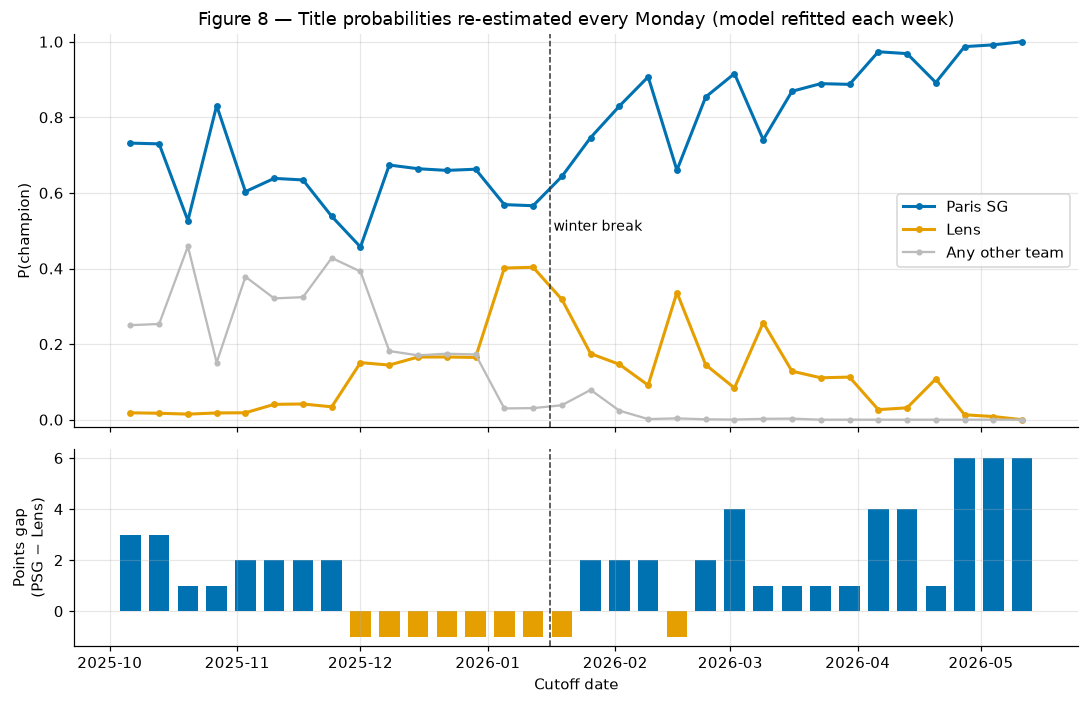

,date,PSG,Lens,ΔP(PSG),results effect,refit effect
3,2025-10-27,0.8310,0.0179,0.3043,0.1135,0.1907
19,2026-02-16,0.6601,0.3365,-0.2470,-0.1190,-0.1280
4,2025-11-03,0.6034,0.0183,-0.2276,-0.0082,-0.2194
9,2025-12-08,0.6738,0.1446,0.2168,0.0838,0.1330
2,2025-10-20,0.5268,0.0147,-0.2030,-0.0809,-0.1221


Mean |weekly move| before the winter break: results 0.035 | refit 0.068  (Monte Carlo noise on each term ≈ 0.005)
Mean |weekly move| after the winter break: results 0.060 | refit 0.025  (Monte Carlo noise on each term ≈ 0.005)
Last Monday before the cutoff (12 Jan 2026): P(PSG) = 0.566 | maximum of P(any other team) over the season: 0.459 on 20 Oct 2025


In [18]:
cuts = pd.date_range("2025-10-06", "2026-05-11", freq="W-MON")
rng = make_rng(6)
film, model_prev = [], None
for cut in cuts:
    past = matches[matches.date < cut]
    model_c = fit_poisson_model(past.h.to_numpy(), past.a.to_numpy(), past.hg.to_numpy(), past.ag.to_numpy())
    state_c = season_state(cut)
    champ = simulate_seasons(model_c, state_c, 20_000, rng)[1] == 0
    # Last week's model applied to this week's standings: isolates the effect of the new results
    p_old_model = np.nan if model_prev is None else np.mean(simulate_seasons(model_prev, state_c, 20_000, rng)[1][:, PSG] == 0)
    model_prev = model_c
    film.append({"date": cut, "PSG": champ[:, PSG].mean(), "Lens": champ[:, LENS].mean(), "PSG_old_model": p_old_model,
                 "other": 1 - champ[:, PSG].mean() - champ[:, LENS].mean(),
                 "gap": int(state_c.base_pts[PSG] - state_c.base_pts[LENS]), "left": state_c.n_matches})
film = pd.DataFrame(film)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.plot(film.date, film.PSG, color=COL["psg"], marker="o", ms=3.5, lw=2, label="Paris SG")
ax.plot(film.date, film.Lens, color=COL["lens"], marker="o", ms=3.5, lw=2, label="Lens")
ax.plot(film.date, film.other, color=COL["other"], marker="o", ms=3, lw=1.5, label="Any other team")
ax.set(ylabel="P(champion)", ylim=(-0.02, 1.02),
       title="Figure 8 — Title probabilities re-estimated every Monday (model refitted each week)")
ax.legend(loc="center right")
ax = axes[1]
ax.bar(film.date, film.gap, width=5, color=np.where(film.gap >= 0, COL["psg"], COL["lens"]))
ax.set(ylabel="Points gap\n(PSG − Lens)", xlabel="Cutoff date")
for a_ in axes:
    a_.axvline(CUTOFF, color=COL["exact"], ls="--", lw=1)
axes[0].text(CUTOFF, 0.5, " winter break", fontsize=9)
plt.tight_layout()
plt.show()

# Decompose each weekly move of P(PSG champion):
#   results effect = P(old model, new standings) - P(old model, old standings)
#   refit effect   = P(new model, new standings) - P(old model, new standings)
film["ΔP(PSG)"] = film.PSG.diff()
film["results effect"] = film.PSG_old_model - film.PSG.shift()
film["refit effect"] = film.PSG - film.PSG_old_model
display(film.loc[film["ΔP(PSG)"].abs().nlargest(5).index, ["date", "PSG", "Lens", "ΔP(PSG)", "results effect", "refit effect"]])
before, after = film.date < CUTOFF, film.date >= CUTOFF
for label, mask in (("before the winter break", before), ("after the winter break", after)):
    print(f"Mean |weekly move| {label}: results {film.loc[mask, 'results effect'].abs().mean():.3f} | "
          f"refit {film.loc[mask, 'refit effect'].abs().mean():.3f}  (Monte Carlo noise on each term ≈ 0.005)")
last = film[film.date < CUTOFF].iloc[-1]
print(f"Last Monday before the cutoff ({last.date:%d %b %Y}): P(PSG) = {last.PSG:.3f} | "
      f"maximum of P(any other team) over the season: {film.other.max():.3f} on {film.date[film.other.idxmax()]:%d %b %Y}")

#### What do we observe?

- **The estimate moves a lot from week to week** — the five largest weekly moves all exceed 20 points. Each weekly move has two causes: the new results (the table changes) and the refit (the model, re-estimated with one more matchday, changes). We separate them by applying last week's model to this week's standings:
  - **before the winter break**, the refit dominates: on average $0.068$ per week against $0.035$ for the results. On 3 November, for instance, $P(\text{PSG})$ falls by $0.23$, of which $0.22$ comes from the refit alone. With 7 to 16 matches per team, one more matchday visibly moves the strength estimates: this is the parameter uncertainty of Section 4.3, observed in real time;
  - **after the winter break**, the results dominate ($0.060$ against $0.025$): the estimates have stabilised, and the probabilities now react mainly to what happens on the pitch — for instance in mid-February, when Lens briefly retook the lead and its title probability jumped to about $0.34$.
- **Early in the season the race was open to others** (up to 46% for "any other team" on 20 October); by the winter break this mass had collapsed to 3%. From March onwards Paris SG's probability rose towards 1, with dips after setbacks, as the remaining matches — and thus the remaining randomness — disappeared.
- The estimate on the last Monday before the cutoff ($0.566$ on 12 January) agrees with the main result ($0.562$), as it should: no match was played between 12 and 16 January.
- **Practical lesson.** A "supercomputer" probability that moves by 20 points in a week deserves to be decomposed: part of the move is information (results), part is noise in the model's inputs.

### 4.5 — Is the input model any good? Calibration on the second half

Paris SG did win the title (76 points against 70 for Lens). This **single outcome neither validates nor refutes** our estimate of $0.56$: an event of probability $0.56$ fails 44% of the time. What can be checked is the model's match-level forecasts: the winter-break model predicted a probability for each of the 153 second-half results, and those results are now known.

We use the **Brier score** $\frac{1}{M}\sum_m \sum_{k \in \{H, D, A\}} (\hat q_{m,k} - o_{m,k})^2$, where $\hat q_{m,k}$ is the forecast probability of outcome $k$ and $o_{m,k} \in \{0, 1\}$ indicates the realised outcome (lower is better; $2/3$ for uniform guessing), and a **reliability diagram**: among the outcomes forecast with probability about $q$, a calibrated model sees a fraction about $q$ occur.

Brier score — uniform: 0.667 | first-half frequencies (H/D/A = [0.5  0.22 0.28]): 0.667 | Poisson model: 0.630
Improvement over frequencies: 0.036 ± 0.050 (95% CLT, paired over matches)


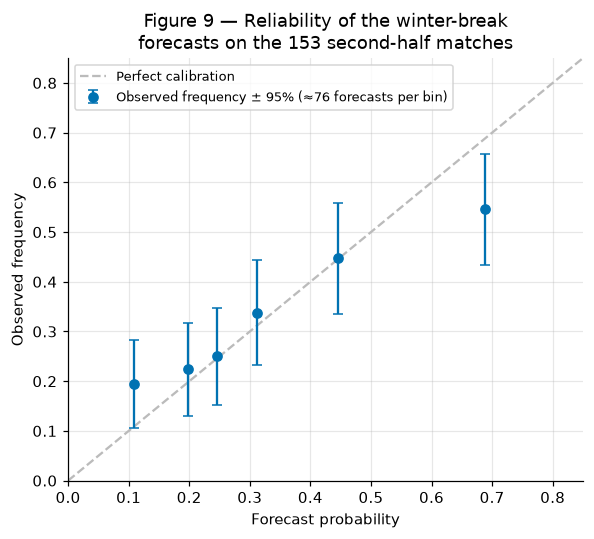

In [19]:
q_model = np.column_stack([P_HOME, P_DRAW, P_AWAY])  # winter-break forecasts for the second half
realised = np.select([remaining.hg > remaining.ag, remaining.hg == remaining.ag], [0, 1], 2)
o = np.eye(3)[realised]
q_base = np.bincount(np.select([played.hg > played.ag, played.hg == played.ag], [0, 1], 2), minlength=3) / len(played)

brier_model = ((q_model - o) ** 2).sum(axis=1)
brier_base = ((q_base - o) ** 2).sum(axis=1)
d = brier_base - brier_model
print(f"Brier score — uniform: {2 / 3:.3f} | first-half frequencies (H/D/A = {q_base.round(2)}): {brier_base.mean():.3f} "
      f"| Poisson model: {brier_model.mean():.3f}")
print(f"Improvement over frequencies: {d.mean():.3f} ± {z * d.std(ddof=1) / np.sqrt(len(d)):.3f} (95% CLT, paired over matches)")

# Reliability diagram: all (forecast, outcome) pairs, equal-count bins
q_flat, o_flat = q_model.ravel(), o.ravel()
edges = np.quantile(q_flat, np.linspace(0, 1, 7))
bins = np.clip(np.searchsorted(edges, q_flat, side="right") - 1, 0, 5)
mean_q = np.array([q_flat[bins == k].mean() for k in range(6)])
freq = np.array([o_flat[bins == k].mean() for k in range(6)])
cnt = np.array([(bins == k).sum() for k in range(6)])

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=COL["other"], ls="--", label="Perfect calibration")
ax.errorbar(mean_q, freq, yerr=z * np.sqrt(freq * (1 - freq) / cnt), fmt="o", color=COL["psg"], capsize=3,
            label=f"Observed frequency ± 95% (≈{cnt.mean():.0f} forecasts per bin)")
ax.set(xlim=(0, 0.85), ylim=(0, 0.85), xlabel="Forecast probability", ylabel="Observed frequency",
       title="Figure 9 — Reliability of the winter-break\nforecasts on the 153 second-half matches")
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout()
plt.show()

#### What do we observe?

- **The model forecasts better than naive rules, but not significantly.** Its Brier score ($0.630$) beats uniform guessing and first-half frequencies (both $0.667$), but the improvement ($0.036 \pm 0.050$) is within sampling noise: 153 matches are not enough to establish forecasting skill.
- **The reliability diagram shows a pattern at the extremes, but no conclusive miscalibration.** Five bins out of six contain the diagonal within their error bars; the highest one does not: outcomes forecast at $\approx 0.69$ occurred only 55% of the time. Together with the lowest bin (forecast $\approx 0.11$, observed 19%), this **suggests over-confidence** — extreme forecasts too extreme — the expected symptom of strengths estimated on small samples (strong teams look stronger than they are, "regression to the mean"). With six bins, three dependent outcomes per match and 153 matches, it is suggestive, not conclusive.
- **Consequence for the title probability.** If the match forecasts are over-confident, so are the season forecasts: the real-world uncertainty at the winter break would be even larger than the model's $0.56$ suggests.

---
## 5 — Limitations and conclusions

### 5.1 — Assumptions and what they imply

**Limits of the input model** (deliberately minimal, see Section 2.5):
- *Independence of the two scores* within a match: in reality low scores are correlated and draws are slightly more frequent than the Poisson product predicts (Dixon & Coles, 1997).
- *Independence across matches and static strengths*: form, injuries, the January transfer window, fatigue from European competitions and motivation at the end of the season are all ignored. Strengths estimated on the first half are applied unchanged to the second.
- *Poisson equidispersion*: the variance of goals equals their mean; over-dispersion would widen all distributions.
- *Small sample*: 36 parameters from 153 matches. The parameter uncertainty (Section 4.3) and the over-confidence (Section 4.5) are direct consequences. Shrinkage (Bayesian priors, ridge penalties) or external information would reduce it — at the cost of a more complex model, which is outside the scope we chose.
- *Tie-breaks*: beyond goal difference, official criteria are replaced by a random draw; this affects at most 0.2% of seasons (Section 3.3).

**Limits of the Monte Carlo method itself:**
- *Monte Carlo is exact for the model, not for the world.* It estimates $p(\hat\theta)$; its error bars say nothing about whether $\hat\theta$, or the model, is right. Reporting "56.2% ± 0.4" without the model uncertainty is technically correct and practically misleading.
- *Slow convergence*: the $1/\sqrt N$ rate means each extra digit costs 100 times more computation. It is harmless here (200 000 seasons take a few seconds) but decisive for expensive simulators.
- *Guarantees are pointwise in $N$*: monitoring a running estimate and stopping when it "looks stable" is not covered by fixed-$N$ confidence intervals (Figure 5).
- *Rare events*: absolute precision is not relative precision. This last point deserves a demonstration.

### 5.2 — When plain Monte Carlo fails: rare events

Proposition 1 gives an **absolute** error $\sqrt{p(1-p)/N}$. For small $p$ the relevant measure is the **relative** error

$$\frac{\sqrt{\operatorname{Var}[\hat p_N]}}{p} = \sqrt{\frac{1-p}{Np}} \approx \frac{1}{\sqrt{Np}},$$

so a 10% relative error requires $N \approx 100/p$ simulations: $10^7$ for $p = 10^{-5}$. With $N \lesssim 1/p$, the estimate is most often exactly $0$ (probability $(1-p)^N \approx e^{-Np}$), and the CLT interval collapses to $\{0\}$.

We illustrate this on a question that can be answered exactly: **the probability that Paris SG collapses**, earning at most $s$ points in its last 17 matches, where $s$ is the largest threshold for which this probability is at most $10^{-5}$.

**Importance sampling** draws from a different distribution $Q$ under which the rare event is frequent, and corrects with the likelihood ratio:

$$P(A) = \mathbb{E}_P[\mathbf{1}_A] = \mathbb{E}_Q\Big[\mathbf{1}_A \frac{dP}{dQ}\Big], \qquad \hat p^{\,\mathrm{IS}}_N = \frac1N\sum_{i=1}^N \mathbf{1}_A(W_i)\,\frac{dP}{dQ}(W_i), \quad W_i \sim Q,$$

which is unbiased as soon as $Q$ charges every outcome that $P$ charges. We **tilt** each match: outcome $k$ (worth $\mathrm{pts}_k \in \{0, 1, 3\}$ to PSG) receives probability $q_{m,k} \propto p_{m,k}\, e^{-t\,\mathrm{pts}_k}$, with $t > 0$ chosen so that PSG earns $s$ points on average under $Q$. The likelihood ratio of a season in which PSG earns $S$ points is then explicit: $\frac{dP}{dQ} = e^{tS}\prod_m \big(\sum_k p_{m,k} e^{-t\,\mathrm{pts}_k}\big)$.

In [20]:
POINTS = np.array([0, 1, 3])
psg_matches = np.flatnonzero((state.h == PSG) | (state.a == PSG))
p_out = np.column_stack([
    np.where(state.h[psg_matches] == PSG, P_AWAY[psg_matches], P_HOME[psg_matches]),  # PSG loses
    P_DRAW[psg_matches],
    np.where(state.h[psg_matches] == PSG, P_HOME[psg_matches], P_AWAY[psg_matches]),  # PSG wins
])
p_out /= p_out.sum(axis=1, keepdims=True)

cdf = np.cumsum(points_pmf(PSG, np.ones(state.n_matches, dtype=bool)))
s_star = int(np.flatnonzero(cdf <= 1e-5)[-1])
p_rare = cdf[s_star]


def tilt(t: float):
    """Tilted outcome probabilities and log normalising constants for PSG's 17 matches."""
    w = p_out * np.exp(-t * POINTS)
    return w / w.sum(axis=1, keepdims=True), np.log(w.sum(axis=1))


t_star = brentq(lambda t: (tilt(t)[0] @ POINTS).sum() - s_star, 0, 20)
q_out, log_norm = tilt(t_star)


def sample_points(probs: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    """Total PSG points over its matches, outcomes drawn independently with the given probabilities."""
    k = (rng.random((n, probs.shape[0], 1)) > np.cumsum(probs, axis=1)[None, :, :-1]).sum(axis=2)
    return POINTS[k].sum(axis=1)


R_RARE, N_RARE = 300, 10_000
rng = make_rng(7)
naive = np.array([(sample_points(p_out, N_RARE, rng) <= s_star).mean() for _ in range(R_RARE)])
is_est = np.empty(R_RARE)
for r_ in range(R_RARE):
    s_pts = sample_points(q_out, N_RARE, rng)
    is_est[r_] = np.mean((s_pts <= s_star) * np.exp(t_star * s_pts + log_norm.sum()))

print(f"Rare event: Paris SG earns at most {s_star} points in its last {len(psg_matches)} matches")
print(f"Exact probability (convolution): {p_rare:.3e} | tilting parameter t = {t_star:.3f}")
for name, est in (("Plain Monte Carlo", naive), ("Importance sampling", is_est)):
    print(f"{name:>20}: mean = {est.mean():.3e} | relative error (sd / p) = {est.std(ddof=1) / p_rare:6.3f} "
          f"| runs returning 0: {np.mean(est == 0):.0%}")
print(f"Variance reduction factor: {naive.var(ddof=1) / is_est.var(ddof=1):,.0f} "
      f"(theory for plain Monte Carlo: relative error = sqrt((1 - p) / (N p)) = {np.sqrt((1 - p_rare) / (N_RARE * p_rare)):.2f})")

Rare event: Paris SG earns at most 15 points in its last 17 matches
Exact probability (convolution): 4.024e-06 | tilting parameter t = 0.964
   Plain Monte Carlo: mean = 3.667e-06 | relative error (sd / p) =  4.678 | runs returning 0: 96%
 Importance sampling: mean = 4.025e-06 | relative error (sd / p) =  0.022 | runs returning 0: 0%
Variance reduction factor: 44,151 (theory for plain Monte Carlo: relative error = sqrt((1 - p) / (N p)) = 4.99)


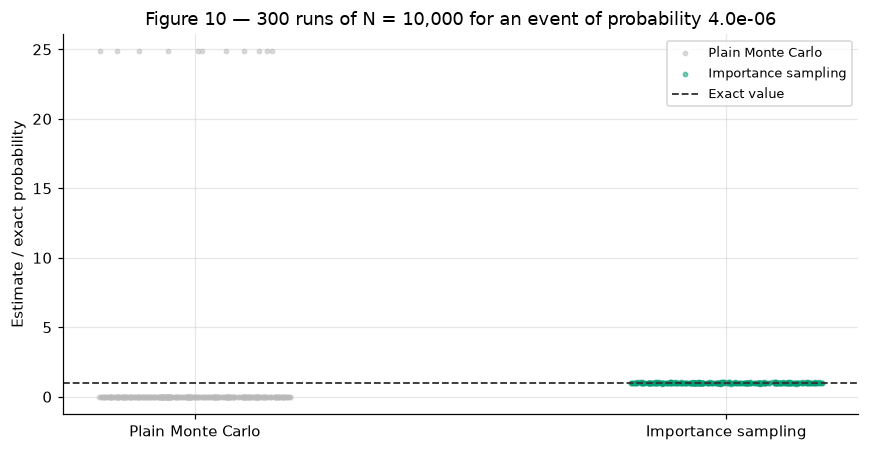

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
jitter = make_rng(8).uniform(-0.18, 0.18, R_RARE)
ax.scatter(0 + jitter, naive / p_rare, s=8, alpha=0.5, color=COL["other"], label="Plain Monte Carlo")
ax.scatter(1 + jitter, is_est / p_rare, s=8, alpha=0.5, color=COL["mc"], label="Importance sampling")
ax.axhline(1, color=COL["exact"], ls="--", lw=1.2, label="Exact value")
ax.set_xticks([0, 1], ["Plain Monte Carlo", "Importance sampling"])
ax.set(ylabel="Estimate / exact probability",
       title=f"Figure 10 — {R_RARE} runs of N = {N_RARE:,} for an event of probability {p_rare:.1e}")
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

#### What do we observe?

- **Plain Monte Carlo is useless here.** With $N = 10\,000$ simulations, 96% of the runs never observe the event and return exactly $0$; the others return $1/N = 10^{-4}$, i.e. **25 times** the true value. The relative error is $4.7$, matching the theoretical $\sqrt{(1-p)/(Np)} \approx 5$. The estimator is unbiased (its mean over 300 runs, $3.7 \times 10^{-6}$, is close to $4.0 \times 10^{-6}$), but a single run tells nothing.
- **Importance sampling solves it.** Under the tilted distribution, PSG's expected number of points equals the threshold, so the collapse becomes a common event, and the likelihood ratio corrects for the change of distribution. The runs scatter by about $2\%$ around the exact value (relative error $0.022$): the variance is divided by about **44 000**, i.e. plain Monte Carlo would need about $4 \times 10^8$ simulations to match it.
- **The catch.** Here the event depends on 17 independent categorical variables and the exact answer is available to check the result. In general, finding a good proposal $Q$ is the hard part; a poorly chosen one can make the variance larger — even infinite — than with plain Monte Carlo, and nothing in a single run warns you.

### 5.3 — Conclusions

**Answer to the research question.** At the 2025/26 winter break, a minimal Poisson model fitted on the first half gives Paris SG a **56% probability of winning the title** (Lens 41%, Marseille 3%). Paris SG is the favourite despite trailing by one point, because its goal record reveals a slightly stronger team. Monte Carlo estimates this model probability to within $\pm 0.4$ point with a guarantee — but **the honest uncertainty is far larger**: re-estimating the model on plausible alternative first halves moves the probability anywhere between roughly $0.1$ and $0.95$, and the model's match forecasts show signs of over-confidence. The defensible statement is therefore: *Paris SG was a modest favourite in a very uncertain race.* Paris SG did win (76 points to 70), which is consistent with this statement but, being a single outcome, cannot confirm it.

**The four questions.**

| | Question | Answer |
|---|---|---|
| Q1 | Precision | $\approx 18\,000$ seasons guarantee $\pm 1$ point (Hoeffding); $200\,000$ give $\pm 0.4$ point for all 18 teams simultaneously. Guarantees verified by 1 000 repetitions. |
| Q2 | Correctness | The simulator reproduces an exact convolution computation; over 4 million seasons its bias is bounded below $0.001$. |
| Q3 | Relevance of the precision | Parameter uncertainty is about 200 times larger than the simulation error; beyond a few thousand simulations, more computation is useless. |
| Q4 | Limits | Small probabilities: the CLT interval collapses once $Np \approx 1$, and plain Monte Carlo is useless at $p \approx 4 \times 10^{-6}$; importance sampling divides the variance by $\approx 44\,000$ when a good proposal is available. |

**When is Monte Carlo the right tool?** When the quantity of interest is an expectation (or probability) under a model one can **simulate** but not **sum**: here a space of $10^{73}$ outcomes, handled in seconds with an error that is unbiased, controllable in advance, and independent of the dimension. Its weaknesses are equally clear: the $1/\sqrt N$ rate, rare events, and above all the fact that its precision is **conditional on the model**.

**Take-aways for practitioners.**
1. A probability is an expectation; Monte Carlo turns any simulator into an estimator with a computable confidence radius.
2. Always report the simulation error **and** the model uncertainty; the first is usually the smaller one.
3. Validate a simulator against exact computations on sub-problems, with repeated independent runs — and report a bound on its bias, not a single pass/fail comparison.
4. Use common random numbers to compare scenarios, and importance sampling (with care) for rare events.

### References

- Lecture notes, *Mathematics of Modern ML*, F. Blibeche, Chapter 1 (law of large numbers, Chebyshev and Hoeffding inequalities, confidence radii).
- N. Metropolis and S. Ulam (1949). *The Monte Carlo method*. Journal of the American Statistical Association, 44(247), 335–341.
- M. J. Maher (1982). *Modelling association football scores*. Statistica Neerlandica, 36(3), 109–118.
- M. J. Dixon and S. G. Coles (1997). *Modelling association football scores and inefficiencies in the football betting market*. Journal of the Royal Statistical Society: Series C, 46(2), 265–280.
- A. B. Owen (2013). *Monte Carlo theory, methods and examples*. Online book (chapters on variance reduction and importance sampling).
- Data: [football-data.co.uk](https://www.football-data.co.uk/francem.php), Ligue 1 2025/26 results.